<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/28_QML_Hardware_Side_Channel_Crosstalk_Attacks/QSVM_PipelineIntegrity_Yeniaras2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QML-PipeGuard: drift-aware behavioural fingerprinting of a QML pipeline, Yeniaras (2026) step by step

This notebook re-implements, runs and checks the experiments of

> Esra Yeniaras,
> "QML-PipeGuard: Drift-Aware Behavioral Fingerprinting for Quantum Machine Learning Pipeline Integrity",
> arXiv:2605.25066 (v1, 24 May 2026). https://doi.org/10.48550/arxiv.2605.25066

**The question of the paper.** A QML model is increasingly run on somebody else's quantum computer. Two things can make the quantum stage
behave differently from what the model owner *declared*: (1) **benign calibration drift** (gate errors, T1/T2 and readout errors change between
recalibrations) and (2) a **sneaky substitution** of the declared circuit by one that gives the *same classifier decisions* and the *same weak
statistics* (for example the same `<Z>` values) but is a different quantum channel. QML-PipeGuard attaches to the pipeline an **observable contract**:
the pipeline is summarised by its **behavioural fingerprint**, the vector of Pauli expectation values `<X1>, <Y1>, <Z1>, <X2>, <Y2>, <Z2>` of its output state.
If the largest deviation from the declared fingerprint is below a calibrated tolerance `eps_A` the deviation is logged as a harmless *drift event*; if it is above,
the run is halted as an integrity violation. A weak contract (`Z1Z2` only) is blind to the substitution, the complete contract is not.

**What the notebook does.**
1. Generates the paper's data (20 `make_moons` points, the stand-in for a two-class intrusion feature space) and shows it.
2. Builds the paper's two-qubit **QSVM pipeline** in Qiskit (`zz_feature_map`, inversion-test kernel circuit), the **honest** channel, the **sneaky** channel
   (an `S` gate on every qubit before the measurement) and the weaker `RZ(pi/6)` variant of the sample-complexity experiment, draws the circuits that are actually executed,
   and transpiles them to the 156-qubit **IBM Heron r2 `ibm_fez`** target (offline, via `FakeFez`).
3. Simulates the hardware with a Qiskit Aer noise model built from the `FakeFez` calibration data of the two qubits the transpiler uses, with an explicit *calibration-drift knob*.
4. Re-checks the paper's theory numbers (shot budgets of Theorem 4 / Corollary 1, the 27-fold and 100-fold reductions, the frame-bound constants of Appendix A, Theorem 1 on the paper's own substitutions).
5. Trains the QSVM and compares it with classical baselines (SVC-RBF, random forest) on identical inputs; shows that the sneaky channel leaves the classifier untouched.
6. **Experiment 1** (detection, Table 8 / Figure 3), **Experiment 2** (sample complexity, Table 9 / Figure 4), **Experiment 3** (drift and tolerance interval, Table 11 / Figure 5),
   and the dual-mode **Algorithm 1** with a hash-chained audit trail.
7. Prints the paper's numbers next to ours with a verdict per claim, a critical reading and exercises.

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime, *Runtime -> Run all*. The first cell installs pinned packages
(if Colab asks for a restart, do it and run all again). No GPU, no account, no IBM token and no quantum hardware are needed.
Nothing is downloaded: the data are generated by scikit-learn and the `ibm_fez` calibration snapshot ships inside `qiskit-ibm-runtime` (`FakeFez`).

**Runtime.** `FAST_MODE = True`: a few minutes (fewer repeats). `FAST_MODE = False`: more repeats and a finer sweep; the elapsed time is printed at the end.
**Important honesty note.** The paper's Experiments 1 and 3 were run on the *real* `ibm_fez` (two jobs of 30 s on 22 May 2026); Experiment 2 on a noise-matched simulator.
Real hardware is not available here, so Experiments 1 and 3 are re-run on a *simulated* Heron-r2-like device: structure and orders of magnitude can be checked, hardware-specific numbers cannot.

## The paper in one page

**Problem.** Runtime integrity of the *quantum stage* of a QML pipeline (VQC, QSVM, QNN). Threat 1: benign calibration drift `E_B = D o E_A`. Threat 2: an adversary
(cloud provider, model owner, or paper author) substitutes `E_A` by `E_B` that (S1) gives the same classifier decisions on the audit set, (S2) agrees with `E_A` on a weak
observable family, but (S3) differs as a channel. The verifier is trusted and holds a reference fingerprint.

**Method.** *Behavioural fingerprint* `Fp(E) = (Tr(O_1 E(rho_ref)), ..., Tr(O_k E(rho_ref)))`; *contract deviation* `Delta = max_O |Tr(O E_B(rho)) - Tr(O E_A(rho))|` (Eq. 8);
the contract holds iff `Delta <= eps_A` (Eq. 2).
* **Theorem 1** (detection): for an informationally complete family with frame-bound constant `C`, `Delta >= delta / C` where `delta = ||E_A - E_B||_diamond`; for the local Pauli family `C = sqrt(3)`.
* **Theorem 4** (budget): `N >= 2 B^2 k ln(2k/eta) / gamma^2` with margin `gamma = delta/C - eps_A`; **Corollary 1** (reference measured too): `N >= 8 B^2 k ln(2k/eta) / gamma^2`.
* **Corollary 2** (drift): the same contract absorbs drift `d` with `d/C <= eps_A`; **Section 5.11**: choose `eps_A` in `[d_typ, delta_min / C]`.
* **Algorithm 1** (dual mode): draw one observable at random per round, collect `N/k` shots, compare with the reference, *halt* if `Delta_t > eps_A`, otherwise log a drift event in a hash-anchored audit trail.

**Pipeline and data (Section 6.1).** `make_moons(n_samples=20, noise=0.1)` (2-D, binary); QSVM with `ZZFeatureMap` (2 qubits, reps = 2); kernel from the inversion test
`|psi_ij> = U(x_i) U(x_j)^dagger |00>`; the fingerprint is measured on this state for the single pair `x_i = (0.4, 1.2)`, `x_j = (1.1, 0.3)` in the six single-qubit Pauli bases
(`H` for X, `S^dagger H` for Y). Honest channel = kernel circuit; sneaky channel = an `S` gate on each qubit just before measurement (keeps `<Z>`, rotates `<X>`, `<Y>` by pi/2).
Weak family `{Z1 Z2}`, complete family `{X1, Y1, Z1, X2, Y2, Z2}`. Parameters: `delta = 0.5`, `eps_A = 0.15`, `eta = 0.05`, `k = 6`, `B = 1`, `C = sqrt(3)`, `gamma = 0.139`, 2280 shots per observable (N = 13,680).

**Headline claims.**
* Budgets: `N ~ 3,420` (Thm 4), `13,680` (Cor 1); `~27x` smaller than with the looser `C = 2 sqrt(2)` of concurrent work, `~100x` together with the precomputed reference; Appendix A, Table 12: Tier 2 (9 observables) `C ~ 2.21`, `N ~ 72,700`; Tier 3 (15) `C ~ 3.73`.
* Experiment 1 (`ibm_fez`, Table 8, Fig. 3): weak contract accepts (max deviation 0.001), complete contract halts (max 0.489 on X2, 3.3x tolerance); Z-type deviations < 0.01; `X1 0.381, Y1 0.105, X2 0.489, Y2 0.358` (three beyond tolerance, `Y1` just below).
* Experiment 2 (Aer + Heron-r2 noise, Table 9, Fig. 4, 20 trials, weakened sneaky `RZ(pi/6)`, true max deviation 0.259, noise-free reference at 1e5 shots): (TPR, FPR) = (1.00, 0.00) at 2280 shots/observable, (0.95, 0.15) at 228, (1.00, 1.00) at 22.
* Experiment 3 (`ibm_fez`, Tables 10-11, Fig. 5): three timepoints, pairwise maxima 0.067 / 0.067 / 0.046, `d_typ = 0.067`, tolerance interval `[0.067, 0.289]` (non-empty), recommended `eps_A = 0.178`.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Code, seeds | repository `schrodinket/QML-PipeGuard` (not used here); `make_moons` "fixed random seed" (value not given) | own implementation; `SEED = 42` everywhere; `# CHOICE` |
| Hardware | real `ibm_fez` (Heron r2, 156 qubits) via Qiskit Runtime `SamplerV2`, Experiments 1 and 3 | **simulation**: `FakeFez` target + Aer noise model rebuilt (thermal relaxation + depolarising + readout) from the calibration snapshot of the two physical qubits the transpiler picks; checked against Aer's own `NoiseModel.from_backend(FakeFez())`. No real-device run (`IBM_TOKEN` unused) |
| Experiment 2 simulator | "noisy Aer simulator with the IBM Heron r2 noise model" | same idea: Aer + `FakeFez` noise |
| Transpilation | default transpiler pass, `optimization_level = 1` | `generate_preset_pass_manager(optimization_level=1, backend=FakeFez())`, `seed_transpiler = SEED` |
| Kernel-circuit state | text: `|psi_ij> = U(x_i) U(x_j)^dagger |00>` | Qiskit kernel convention `U(x_j)^dagger U(x_i) |00>` (apply `U(x_i)` first). The text's operator order (`U(x_j)^dagger` applied first) gives an ideal `Y1` deviation of 1.34 instead of the paper's 0.105 and an ideal weak-sneaky maximum of 0.47 instead of the paper's 0.259; the Qiskit order gives 0.095 and 0.256 (both orders are computed below). `# CHOICE` |
| `S` placement | "immediately before measurement" | after the state, **before** the basis-change gates (the only placement that changes `<X>`, `<Y>`) |
| Y-basis change | "`S^dagger H` before Y measurement" | standard `Sdg` then `H` in circuit order. `# CHOICE` |
| 7 circuits per channel | `Z1Z2` plus six single-qubit Paulis (14 circuits) | same; each circuit measures both qubits and uses the marginal / parity needed |
| Train / test split | not stated ("20 samples") | stratified 70 / 30 (14 / 6), repeated over 20 seeds because 6 test points are too few for one number; the classifier accuracy is not a claim of the paper |
| Bandwidth tuning, hyper-parameters | none | none: raw coordinates are encoded as in the paper, `SVC(C = 1)`; `# CHOICE` |
| Reference fingerprint | ideal simulator, 1e5 shots (Exp. 2); exact specification (Algorithm 1, line 2) | exact statevector values for Algorithm 1 and Table 8 comparisons; 1e5-shot noise-free sampling for Experiment 2 (as in the paper) |
| Trials in Experiment 2 | 20 per budget | 20 (reported next to the paper) and a larger number (`N_TRIALS_E2`) for tight confidence intervals |
| Drift | three timepoints minutes apart on real hardware | (a) the same protocol on a *static* simulated device (no calibration change: the pure shot-noise floor), (b) simulated calibration snapshots with log-normal jitter `sigma`, (c) a global degradation factor |
| Independent shots | hardware shots are independent | Aer uses a different seed for honest and sneaky runs (identical seeds would make `Z` deviations exactly 0) |
| Frame constants | tabulated in Appendix A (script `analysis/frame_bound.py`) | recomputed here (sign enumeration for 15 observables, multi-start Nelder-Mead for 6 and 9) |
| Classical baselines | none | SVC-RBF, SVC-linear and random forest on the identical 2-D inputs; for the detection task the "weak" audits (decision agreement, `<Z>` only) are the baselines |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("qiskit", "qiskit_aer", "qiskit_ibm_runtime", "qiskit_machine_learning") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit stack already present; skipping pip install.")

Qiskit stack already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
import numpy as np
FAST_MODE = False     # True: class demo (a few minutes). False: more repeats / finer sweeps (see the runtime printed at the end).
SEED      = 42           # CHOICE: the paper gives no seed
IBM_TOKEN = ""           # not used: the real-hardware runs of the paper are replaced by a noisy Aer simulation of FakeFez
DATA_DIR  = "data"       # cache folder (nothing is downloaded: the data are generated)

# Data and pipeline (paper Sec. 6.1) ------------------------------------------------------------------------
N_SAMPLES, MOONS_NOISE = 20, 0.1       # make_moons(20, noise 0.1)
TEST_SIZE   = 0.3                      # CHOICE: split of the 20 points for the classifier baselines (14 / 6)
FM_REPS     = 2                        # ZZFeatureMap repetitions
XI, XJ      = (0.4, 1.2), (1.1, 0.3)   # the single pair of inputs on which every fingerprint is measured
WEAK_ANGLE  = np.pi / 6                # RZ angle of the weakened sneaky channel (Experiment 2)

# Contract parameters (paper Sec. 6.1) --------------------------------------------------------------------------
DELTA, EPS_A, ETA, B_NORM = 0.5, 0.15, 0.05, 1.0     # adversarial separation, tolerance, 1 - confidence, operator-norm bound
C_LOCAL      = float(np.sqrt(3))                      # frame-bound constant of the local Pauli family
SHOTS_PER_OBS = 2280                                  # shots per observable (N = 13,680 over six observables)
SHOTS_KERNEL  = 1024                                  # shots per kernel entry in the noisy-kernel check

# Repeats (the paper reports a single hardware run for Exp. 1 and 3 and 20 trials for Exp. 2) -------------------
N_REPEAT_E1   = 30  if FAST_MODE else 200            # repeated detection runs (Experiment 1)
N_TRIALS_E2   = 40  if FAST_MODE else 200            # trials per budget (Experiment 2); the first 20 are also reported as "paper protocol"
BUDGETS_E2    = [2280, 1140, 570, 228, 114, 22] if FAST_MODE else [2280, 1710, 1140, 855, 570, 400, 228, 114, 57, 22]
N_REPEAT_E3   = 30  if FAST_MODE else 200            # repeats of the three-timepoint drift protocol
SIGMAS_E3     = [0.0, 0.1, 0.25, 0.5, 1.0]            # log-normal jitter of the calibration numbers between snapshots
N_REPEAT_SIG  = 10  if FAST_MODE else 50
SCALES_E3     = [1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0]   # global degradation factor of all error rates (T1, T2 divided by it)
N_REPEAT_SCALE = 20 if FAST_MODE else 100
N_ALG1_TRIALS  = 60 if FAST_MODE else 200            # Monte-Carlo runs of Algorithm 1 (rounds to detection)
MAX_ROUNDS     = 30
N_RELIABILITY  = 10 if FAST_MODE else 20              # classifier-baseline splits

In [3]:
import os, time, json, hashlib, warnings, itertools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, scipy
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from scipy.optimize import minimize

import qiskit, qiskit_aer, qiskit_ibm_runtime, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit import Measure, Parameter
from qiskit.circuit.library import zz_feature_map, SXGate, XGate, RZGate, CZGate, IGate
from qiskit.providers.backend import QubitProperties
from qiskit.transpiler import Target, InstructionProperties
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.noise.device.models import basic_device_gate_errors, basic_device_readout_errors
from qiskit_ibm_runtime.fake_provider import FakeFez
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.utils import algorithm_globals

warnings.filterwarnings("ignore")
algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T0 = time.time()
RES = {}      # results collected for the final comparison table
print("qiskit", qiskit.__version__, "| aer", qiskit_aer.__version__, "| ibm-runtime", qiskit_ibm_runtime.__version__,
      "| qiskit-machine-learning", qiskit_machine_learning.__version__)
print("numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| FAST_MODE =", FAST_MODE, "| SEED =", SEED)

qiskit 2.5.2 | aer 0.17.2 | ibm-runtime 0.50.0 | qiskit-machine-learning 0.9.1
numpy 2.5.4 | scikit-learn 1.9.1 | scipy 1.18.1 | FAST_MODE = False | SEED = 42


## Dataset Exploration and Visualisation

The paper's data are produced by scikit-learn's `make_moons` generator (20 points, noise 0.1): two interleaved half-moons, a two-feature, two-class stand-in for a
benign / attack feature space, following the QSVM intrusion-detection set-up of Kalinin and Krundyshev. The paper does not give the generator seed, so `SEED = 42` is used.
There is no download: the data *are* the generator output, exactly as in the paper (no invented labels).

The cell below prints the shape, feature names, original label values and class counts, then draws

* the real **class distribution** (bar chart),
* a **2-D scatter of the real observations coloured by their ground-truth label**: (a) the raw features (the paper encodes these raw coordinates into the `ZZFeatureMap`; the two stars are the fixed input pair
  `x_i`, `x_j` of the fingerprint), (b) the PCA coordinates fitted on the training split only, (c) the same coordinates scaled to `[0, pi]` with a scaler fitted on the training split only (test points clipped),
  the convention used for angle encoding in the other notebooks of this project. The paper itself does *not* rescale, so (c) is for orientation only.

In [4]:
X, y = make_moons(n_samples=N_SAMPLES, noise=MOONS_NOISE, random_state=SEED)
FEATURES = ["x1", "x2"]
CLASS_NAMES = {0: "class 0 (upper moon, stand-in 'benign')", 1: "class 1 (lower moon, stand-in 'attack')"}
df = pd.DataFrame(X, columns=FEATURES); df["label"] = y
print("dataset shape:", X.shape, "| labels:", y.shape)
print("feature names:", FEATURES)
print("original label values:", sorted(np.unique(y).tolist()), "->", CLASS_NAMES)
print("class counts:", df["label"].value_counts().sort_index().to_dict())
print("feature ranges: x1 [%.2f, %.2f], x2 [%.2f, %.2f]" % (X[:, 0].min(), X[:, 0].max(), X[:, 1].min(), X[:, 1].max()))
display(df.round(3).T)

idx = np.arange(N_SAMPLES)
idx_tr, idx_te = train_test_split(idx, test_size=TEST_SIZE, stratify=y, random_state=SEED)
Xtr, Xte, ytr, yte = X[idx_tr], X[idx_te], y[idx_tr], y[idx_te]
print("train / test sizes:", len(idx_tr), len(idx_te), "| train class counts", np.bincount(ytr), "| test class counts", np.bincount(yte))

dataset shape: (20, 2) | labels: (20,)
feature names: ['x1', 'x2']
original label values: [0, 1] -> {0: "class 0 (upper moon, stand-in 'benign')", 1: "class 1 (lower moon, stand-in 'attack')"}
class counts: {0: 10, 1: 10}
feature ranges: x1 [-1.12, 1.96], x2 [-0.50, 1.07]


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
x1,1.146,1.522,1.149,0.792,-0.942,-0.132,0.031,0.510,1.926,1.425,0.595,0.729,-1.119,1.955,0.206,0.016,-0.749,0.075,0.883,-0.453
x2,0.154,-0.082,-0.501,0.491,0.378,1.068,0.155,0.932,0.155,-0.444,-0.208,0.680,-0.041,0.652,0.845,-0.247,0.675,0.316,-0.482,0.932
label,0.000,1.000,1.000,0.000,0.000,0.000,1.000,0.000,1.000,1.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000,1.000,1.000,0.000


train / test sizes: 14 6 | train class counts [7 7] | test class counts [3 3]


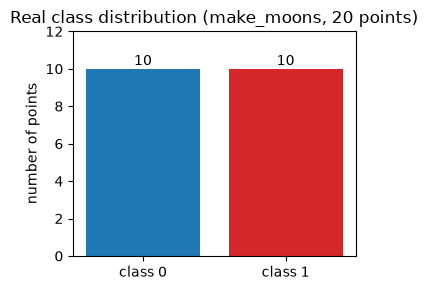

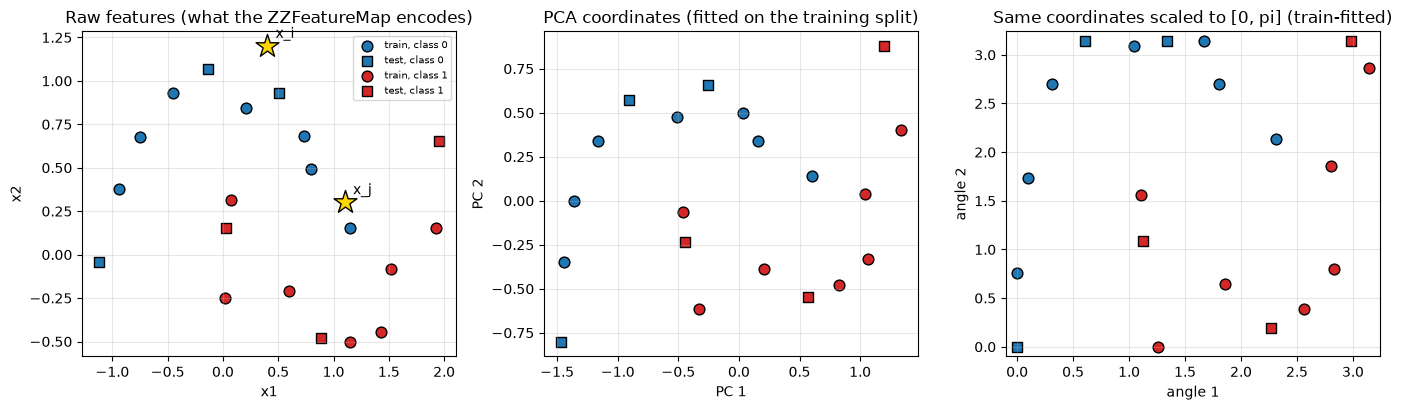

The fixed fingerprint pair x_i = (0.4, 1.2), x_j = (1.1, 0.3) lies inside the data cloud: x_i near the upper moon, x_j near the lower moon.


In [5]:
COL = {0: "tab:blue", 1: "tab:red"}
fig, ax = plt.subplots(figsize=(3.6, 3.0))
counts = np.bincount(y)
ax.bar([CLASS_NAMES[c].split(" (")[0] for c in (0, 1)], counts, color=[COL[0], COL[1]])
for i, c in enumerate(counts): ax.text(i, c + 0.2, str(c), ha="center")
ax.set_ylabel("number of points"); ax.set_title("Real class distribution (make_moons, 20 points)"); ax.set_ylim(0, counts.max() + 2)
plt.tight_layout(); plt.show()

pca = PCA(n_components=2, random_state=SEED).fit(Xtr)            # fitted on the training split only
Ptr, Pte = pca.transform(Xtr), pca.transform(Xte)
mm = MinMaxScaler((0, np.pi)).fit(Ptr)                           # fitted on the training split only
Atr, Ate = mm.transform(Ptr), np.clip(mm.transform(Pte), 0, np.pi)

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
def scatter(ax, A, B, title, xl, yl):
    for c in (0, 1):
        ax.scatter(A[ytr == c, 0], A[ytr == c, 1], c=COL[c], s=60, edgecolor="k", label=f"train, {CLASS_NAMES[c].split(' (')[0]}")
        ax.scatter(B[yte == c, 0], B[yte == c, 1], c=COL[c], s=60, edgecolor="k", marker="s", label=f"test, {CLASS_NAMES[c].split(' (')[0]}")
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.grid(alpha=0.3)
scatter(axs[0], Xtr, Xte, "Raw features (what the ZZFeatureMap encodes)", "x1", "x2")
axs[0].scatter(*zip(XI, XJ), marker="*", s=300, c="gold", edgecolor="k", zorder=5)
axs[0].annotate("x_i", XI, textcoords="offset points", xytext=(6, 6)); axs[0].annotate("x_j", XJ, textcoords="offset points", xytext=(6, 6))
scatter(axs[1], Ptr, Pte, "PCA coordinates (fitted on the training split)", "PC 1", "PC 2")
scatter(axs[2], Atr, Ate, "Same coordinates scaled to [0, pi] (train-fitted)", "angle 1", "angle 2")
axs[2].set_xlim(-0.1, np.pi + 0.1); axs[2].set_ylim(-0.1, np.pi + 0.1)
axs[0].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()
print("The fixed fingerprint pair x_i = %s, x_j = %s lies inside the data cloud: x_i near the upper moon, x_j near the lower moon." % (XI, XJ))

## Quantum Circuit Architecture

The pipeline of the paper has **no trainable quantum parameters**: it is a quantum-kernel (QSVM) pipeline whose only circuit is the *encoding* `ZZFeatureMap(2, reps=2)`.
The circuit that is executed to build a fingerprint is the **inversion-test** circuit

`|psi_ij> = U(x_j)^dagger U(x_i) |00>`  (Qiskit kernel convention, see the table above),

followed by a Pauli basis change and a measurement of both qubits. We draw the circuits that are really executed, one drawing per distinct architecture:

1. **honest** channel (shown for the `X1` fingerprint circuit; the other basis settings differ only in the basis-change gates),
2. **sneaky** channel: an `S` gate on each qubit between the state preparation and the basis change (a local unitary: keeps every `Z` statistic, rotates `X`/`Y`),
3. **weak sneaky** channel of Experiment 2: `RZ(pi/6)` on each qubit instead of `S`,
4. the **honest circuit after transpilation to the `ibm_fez` (FakeFez) native gate set** `{cz, rz, sx, x}` with `optimization_level = 1`: this is the circuit the Aer simulator runs.

Assumptions where the paper omits details: entanglement pattern of the `ZZFeatureMap` (irrelevant for two qubits), the exact kernel-state ordering (see above), the physical qubits (chosen by the transpiler, as in the paper) and the placement of the `S` gate (before the basis change).

honest (X1 circuit, decomposed)              qubits=2  depth= 22  size= 31  trainable params=0  data-encoding params (bound to x_i, x_j)=4  ops={'u': 21, 'cx': 8, 'measure': 2}


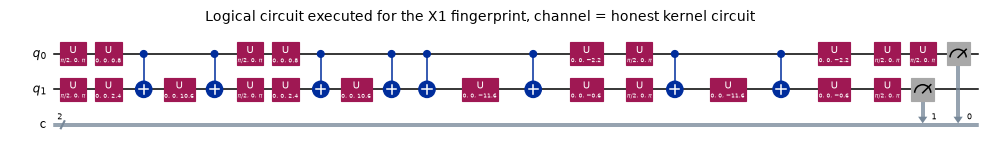

sneaky (X1 circuit, decomposed)              qubits=2  depth= 23  size= 33  trainable params=0  data-encoding params (bound to x_i, x_j)=4  ops={'u': 23, 'cx': 8, 'measure': 2}


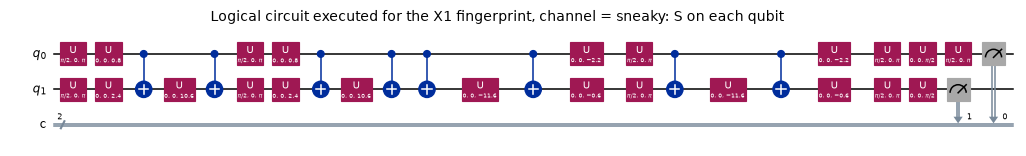

weak (X1 circuit, decomposed)                qubits=2  depth= 23  size= 33  trainable params=0  data-encoding params (bound to x_i, x_j)=4  ops={'u': 23, 'cx': 8, 'measure': 2}


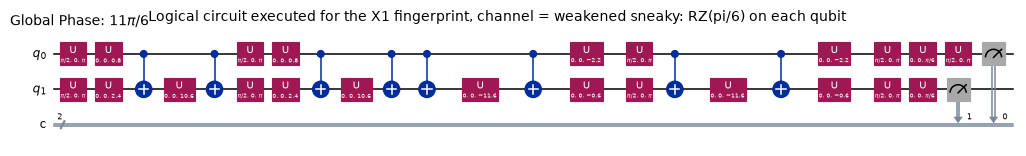

In [6]:
FM = zz_feature_map(feature_dimension=2, reps=FM_REPS)      # the paper's "standard ZZFeatureMap with two repetitions"
OBS6 = ["X1", "Y1", "Z1", "X2", "Y2", "Z2"]                  # complete (local Pauli) family
OBS7 = ["ZZ"] + OBS6                                         # weak observable Z1Z2 + the complete family (7 circuits per channel)
KINDS = {"honest": "honest kernel circuit", "sneaky": "sneaky: S on each qubit", "weak": f"weakened sneaky: RZ(pi/6) on each qubit"}

def state_circuit(kind="honest", xi=XI, xj=XJ, order="qiskit"):
    """State whose Pauli expectations form the fingerprint. order='qiskit': U(xj)^dag U(xi)|00>; order='text': U(xi) U(xj)^dag|00>."""
    qc = QuantumCircuit(2)
    if order == "qiskit":      # apply U(xi) first, then U(xj)^dagger  (what FidelityQuantumKernel builds)
        qc.compose(FM.assign_parameters(list(xi)), inplace=True)
        qc.compose(FM.assign_parameters(list(xj)).inverse(), inplace=True)
    else:                      # paper text: U(xi) U(xj)^dagger |00>  = apply U(xj)^dagger first, then U(xi)
        qc.compose(FM.assign_parameters(list(xj)).inverse(), inplace=True)
        qc.compose(FM.assign_parameters(list(xi)), inplace=True)
    if kind == "sneaky":
        qc.s(0); qc.s(1)
    elif kind == "weak":
        qc.rz(WEAK_ANGLE, 0); qc.rz(WEAK_ANGLE, 1)
    return qc

def basis_change(qc, obs):
    if obs == "ZZ" or obs[0] == "Z":
        return
    q = int(obs[1]) - 1
    if obs[0] == "X":
        qc.h(q)
    else:
        qc.sdg(q); qc.h(q)            # CHOICE: standard Y-basis change (S^dagger, then H)

def measured_circuit(obs, kind="honest", xi=XI, xj=XJ):
    qc = QuantumCircuit(2, 2)
    qc.compose(state_circuit(kind, xi, xj), inplace=True)
    basis_change(qc, obs)
    qc.measure([0, 1], [0, 1])
    return qc

def describe(qc, label):
    n_data_params = len(FM.parameters) * 2
    print(f"{label:<44s} qubits={qc.num_qubits}  depth={qc.depth():>3d}  size={qc.size():>3d}  "
          f"trainable params=0  data-encoding params (bound to x_i, x_j)={n_data_params}  ops={dict(qc.count_ops())}")

fig_circ = {}
for kind in ("honest", "sneaky", "weak"):
    qc = measured_circuit("X1", kind)
    describe(qc.decompose(reps=2), f"{kind} (X1 circuit, decomposed)")
    fig = qc.decompose(reps=2).draw("mpl", fold=40, scale=0.55)
    fig.suptitle(f"Logical circuit executed for the X1 fingerprint, channel = {KINDS[kind]}", fontsize=10)
    display(fig); plt.close(fig)

physical qubits chosen by the transpiler on fake_fez : [0, 1]
honest X1 circuit, transpiled to FakeFez     qubits=2  depth= 38  size= 49  trainable params=0  data-encoding params (bound to x_i, x_j)=4  ops={'rz': 26, 'sx': 15, 'cz': 6, 'measure': 2}


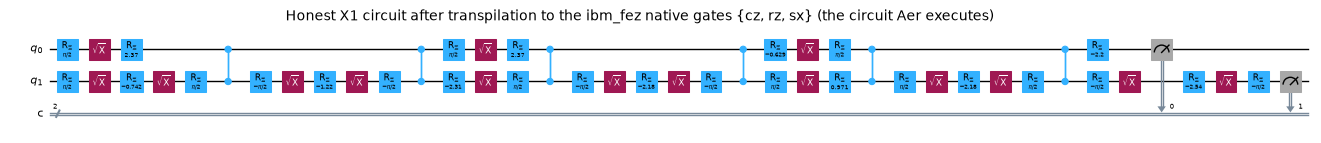

equivalence assertion passed: all 21 transpiled circuits equal their logical circuits up to global phase.
two-qubit gates: honest 6 CZ; 1-qubit depth after transpilation: 38


In [7]:
# ---------- transpile to ibm_fez (FakeFez) exactly as the paper: default pass manager, optimization_level=1 ----------
BACKEND = FakeFez()
PM = generate_preset_pass_manager(optimization_level=1, backend=BACKEND, seed_transpiler=SEED)

def reduce2(isa):
    """The transpiled circuit is 156 qubits wide but touches two physical qubits; keep only those (virtual qubit i -> new qubit i)."""
    phys = list(isa.layout.final_index_layout())
    pos = {p: i for i, p in enumerate(phys)}
    out = QuantumCircuit(2, 2)
    for inst in isa.data:
        qb = [pos[isa.find_bit(q).index] for q in inst.qubits]
        cb = [isa.find_bit(c).index for c in inst.clbits]
        out.append(inst.operation, qb, cb)
    return out, phys

_ISA = {}
def isa2(obs, kind="honest", xi=XI, xj=XJ):
    key = (obs, kind, tuple(xi), tuple(xj))
    if key not in _ISA:
        _ISA[key] = reduce2(PM.run(measured_circuit(obs, kind, xi, xj)))
    return _ISA[key]

c_x1, PHYS = isa2("X1", "honest")
for o in OBS7:
    for k in ("honest", "sneaky", "weak"):
        assert isa2(o, k)[1] == PHYS, "the transpiler must use the same physical qubits for every circuit"
print("physical qubits chosen by the transpiler on", BACKEND.name, ":", PHYS)
describe(c_x1, "honest X1 circuit, transpiled to FakeFez")
fig = c_x1.draw("mpl", fold=45, scale=0.5)
fig.suptitle("Honest X1 circuit after transpilation to the ibm_fez native gates {cz, rz, sx} (the circuit Aer executes)", fontsize=10)
display(fig); plt.close(fig)

# equivalence: the transpiled circuit prepares the same state as the logical circuit (up to a global phase)
def strip(qc): return qc.remove_final_measurements(inplace=False)
for o in OBS7:
    for k in ("honest", "sneaky", "weak"):
        logical = strip(measured_circuit(o, k))
        assert Statevector(strip(isa2(o, k)[0])).equiv(Statevector(logical)), (o, k)
print("equivalence assertion passed: all 21 transpiled circuits equal their logical circuits up to global phase.")
print(f"two-qubit gates: honest {c_x1.count_ops().get('cz', 0)} CZ; 1-qubit depth after transpilation: {c_x1.depth()}")

### The simulated device: an Aer noise model from the `FakeFez` calibration data

The real experiments ran on `ibm_fez`; here the device is replaced by an Aer noise model built from the calibration snapshot shipped with `FakeFez` (the same recipe as Aer's
`NoiseModel.from_backend`: depolarising error scaled to the reported gate error plus thermal relaxation from T1/T2 and the gate duration, and a readout error per qubit).
Because Aer's `from_backend` on all 156 qubits is slow (about 20 s per model), the model is rebuilt for the **two physical qubits that are used**, from a small `Target`. This also lets us
*change the calibration numbers* to simulate drift. The cell checks that the reduced model gives exactly the same counts as Aer's full `NoiseModel.from_backend(FakeFez())`.

In [8]:
TG = BACKEND.target
def calib(qubits):
    a, b = qubits
    c = {"t1": [TG.qubit_properties[q].t1 for q in qubits], "t2": [TG.qubit_properties[q].t2 for q in qubits],
         "ro": [TG["measure"][(q,)].error for q in qubits], "ro_dur": [TG["measure"][(q,)].duration for q in qubits]}
    for g in ("sx", "x", "id"):
        c[g] = [TG[g][(q,)].error for q in qubits]; c[g + "_dur"] = [TG[g][(q,)].duration for q in qubits]
    c["cz"] = TG["cz"][(a, b)].error; c["cz_dur"] = TG["cz"][(a, b)].duration
    return c

def make_target(c):
    tg = Target(num_qubits=2, qubit_properties=[QubitProperties(t1=c["t1"][i], t2=min(c["t2"][i], 2 * c["t1"][i]), frequency=5e9) for i in range(2)])
    tg.add_instruction(SXGate(), {(i,): InstructionProperties(duration=c["sx_dur"][i], error=c["sx"][i]) for i in range(2)})
    tg.add_instruction(XGate(),  {(i,): InstructionProperties(duration=c["x_dur"][i], error=c["x"][i]) for i in range(2)})
    tg.add_instruction(IGate(),  {(i,): InstructionProperties(duration=c["id_dur"][i], error=c["id"][i]) for i in range(2)})
    tg.add_instruction(RZGate(Parameter("t")), {(i,): InstructionProperties(duration=0.0, error=0.0) for i in range(2)})
    tg.add_instruction(CZGate(), {(0, 1): InstructionProperties(duration=c["cz_dur"], error=c["cz"]), (1, 0): InstructionProperties(duration=c["cz_dur"], error=c["cz"])})
    tg.add_instruction(Measure(), {(i,): InstructionProperties(duration=c["ro_dur"][i], error=c["ro"][i]) for i in range(2)})
    return tg

def noise_from_calib(c):
    tg = make_target(c)
    nm = NoiseModel(basis_gates=["cz", "rz", "sx", "x", "id"])
    for qubits, err in basic_device_readout_errors(None, target=tg):
        nm.add_readout_error(err, qubits)
    for name, qubits, err in basic_device_gate_errors(None, gate_error=True, thermal_relaxation=True, target=tg):
        nm.add_quantum_error(err, name, qubits)
    return nm

def perturb_calib(c, rng, sigma=0.0, scale=1.0):
    """Drifted calibration snapshot: error rates *scale*, T1/T2 /scale, each number times a log-normal jitter exp(sigma*N(0,1))."""
    d = {}
    for k, v in c.items():
        if k.endswith("_dur"):
            d[k] = v
        elif k in ("t1", "t2"):
            d[k] = [float(t / scale * np.exp(-sigma * rng.normal())) for t in v]
        elif isinstance(v, list):
            d[k] = [float(min(0.75, e * scale * np.exp(sigma * rng.normal()))) for e in v]
        else:
            d[k] = float(min(0.75, v * scale * np.exp(sigma * rng.normal())))
    return d

CAL0 = calib(PHYS)
print("calibration snapshot of FakeFez for physical qubits", PHYS)
print(pd.DataFrame({"qubit " + str(q): {"T1 (us)": CAL0["t1"][i] * 1e6, "T2 (us)": CAL0["t2"][i] * 1e6, "readout error": CAL0["ro"][i], "sx error": CAL0["sx"][i]} for i, q in enumerate(PHYS)}).round(5))
print("cz error on the pair: %.4f" % CAL0["cz"])
NM0 = noise_from_calib(CAL0)
SIM_NOISY = AerSimulator(noise_model=NM0)
SIM_IDEAL = AerSimulator()

def expval_from_counts(counts, obs, shots):
    tot = 0
    for b, n in counts.items():
        bits = b[::-1]                                      # bits[i] = classical bit i = qubit i
        v = (-1) ** (int(bits[0]) + int(bits[1])) if obs == "ZZ" else (-1) ** int(bits[int(obs[1]) - 1])
        tot += v * n
    return tot / shots

def measure_fp(kind, obs_list, sim, shots, seed, xi=XI, xj=XJ):
    circs = [isa2(o, kind, xi, xj)[0] for o in obs_list]
    res = sim.run(circs, shots=shots, seed_simulator=int(seed)).result()
    return np.array([expval_from_counts(res.get_counts(i), o, shots) for i, o in enumerate(obs_list)])

def fp_exact(kind, obs_list=OBS7, xi=XI, xj=XJ, order="qiskit"):
    sv = Statevector(state_circuit(kind, xi, xj, order)); out = []
    for o in obs_list:
        lab = "ZZ" if o == "ZZ" else ["I", "I"]
        if o != "ZZ":
            lab[1 - (int(o[1]) - 1)] = o[0]; lab = "".join(lab)
        out.append(sv.expectation_value(SparsePauliOp(lab)).real)
    return np.array(out)

# validation against Aer's own full 156-qubit noise model (slow, run once)
t = time.time()
NM_FULL = NoiseModel.from_backend(BACKEND)
SIM_FULL = AerSimulator(noise_model=NM_FULL)
OBS_CHECK = ["ZZ", "X1", "X2", "Y1"]
fp_full = np.array([expval_from_counts(SIM_FULL.run(PM.run(measured_circuit(o, "honest")), shots=20000, seed_simulator=7).result().get_counts(), o, 20000) for o in OBS_CHECK])
fp_red = measure_fp("honest", OBS_CHECK, SIM_NOISY, 20000, 7)
print("max |reduced - full from_backend| over %s at 20000 shots: %.4f (shot-noise std ~0.007)   (took %.0f s)" % (OBS_CHECK, np.abs(fp_full - fp_red).max(), time.time() - t))
assert np.abs(fp_full - fp_red).max() < 0.03
FP_IDEAL = {k: fp_exact(k) for k in ("honest", "sneaky", "weak")}
print("\nexact (noise-free) fingerprints, Qiskit order:")
print(pd.DataFrame(FP_IDEAL, index=OBS7).round(3).T)
FP_H_NOISY = measure_fp("honest", OBS7, SIM_NOISY, 200000, SEED)
print("\nhonest fingerprint on the simulated Fez (200k shots) vs exact:")
print(pd.DataFrame({"exact": FP_IDEAL["honest"], "noisy": FP_H_NOISY, "|diff|": np.abs(FP_H_NOISY - FP_IDEAL["honest"])}, index=OBS7).round(3).T)
RES["honest_noise_dev_max"] = float(np.abs(FP_H_NOISY - FP_IDEAL["honest"])[1:].max())

calibration snapshot of FakeFez for physical qubits [0, 1]
                qubit 0    qubit 1
T1 (us)        48.80621  255.70517
T2 (us)        42.37960  302.79087
readout error   0.01147    0.01172
sx error        0.00076    0.00018
cz error on the pair: 0.0102


max |reduced - full from_backend| over ['ZZ', 'X1', 'X2', 'Y1'] at 20000 shots: 0.0102 (shot-noise std ~0.007)   (took 49 s)

exact (noise-free) fingerprints, Qiskit order:
           ZZ     X1     Y1     Z1     X2     Y2     Z2
honest  0.765 -0.298 -0.393  0.767  0.494 -0.066  0.763
sneaky  0.765  0.393 -0.298  0.767  0.066  0.494  0.763
weak    0.765 -0.062 -0.489  0.767  0.461  0.190  0.763



honest fingerprint on the simulated Fez (200k shots) vs exact:
           ZZ     X1     Y1     Z1     X2     Y2     Z2
exact   0.765 -0.298 -0.393  0.767  0.494 -0.066  0.763
noisy   0.668 -0.263 -0.346  0.685  0.442 -0.055  0.685
|diff|  0.097  0.035  0.047  0.082  0.052  0.010  0.078


## 1. The theory numbers: budgets, frame-bound constants, Theorem 1

Before any simulation, the closed-form numbers of the paper can be recomputed exactly.

* **Margin and budgets.** `gamma = delta / C - eps_A`; Theorem 4: `N >= 2 B^2 k ln(2k/eta) / gamma^2`; Corollary 1 (reference measured as well): `N >= 8 B^2 k ln(2k/eta) / gamma^2`.
* **"27-fold" and "100-fold".** The paper compares its `C = sqrt(3)` with `C = 2 sqrt(2)` of concurrent work; the budget scales as `1/gamma^2`.
* **Frame-bound constants (Appendix A, Table 12).** `C(O_A) = sup { sum_O |c_O| : M = sum_O c_O O, ||M||_op <= 1 }`. For 6 local Paulis the paper derives `sqrt(3)`; for 9 and 15 observables it gives `~2.21` and `~3.73` by numerical search.
  We recompute them: for the full 15-Pauli family the span is every traceless Hermitian operator and the supremum equals `max_s ||sum_O s_O O||_1 / 4` over sign vectors `s` (exact enumeration); for 6 and 9 observables we use
  a multi-start Nelder-Mead search over the coefficients (a lower bound on the supremum).
* **Theorem 1 on the paper's own substitutions.** For a local-unitary substitution `E_B = V . E_A`, `delta = ||id - V.V^dagger||_diamond` is `2 sin(a/2)` where `a < pi` is the angular spread of the eigenvalues of `V` (or 2 if it
  is not smaller than pi), and `sup_rho Delta = max_O ||V^dagger O V - O||_op`. Theorem 1 claims `sup Delta >= delta / C`.

In [9]:
def margin(delta, C, eps): return delta / C - eps
def N_thm4(k, gam, eta=ETA, B=B_NORM): return 2 * B**2 * k * np.log(2 * k / eta) / gam**2
def N_cor1(k, gam, eta=ETA, B=B_NORM): return 8 * B**2 * k * np.log(2 * k / eta) / gam**2

gam = margin(DELTA, C_LOCAL, EPS_A)
C_OLD = 2 * np.sqrt(2)
gam_old = margin(DELTA, C_OLD, EPS_A)
fold27 = (gam / gam_old) ** 2
print(f"gamma = delta/C - eps_A = {DELTA}/{C_LOCAL:.4f} - {EPS_A} = {gam:.4f}                   (paper: 0.139)")
print(f"Theorem 4  N = {N_thm4(6, gam):,.0f} total shots ({N_thm4(6, gam)/6:,.0f} per observable)            (paper: ~3,420)")
print(f"Corollary 1 N = {N_cor1(6, gam):,.0f} total shots ({N_cor1(6, gam)/6:,.0f} per observable)          (paper: ~13,680 = 6 x 2,280)")
print(f"C = 2 sqrt(2): gamma_old = {gam_old:.4f}; budget ratio (gamma/gamma_old)^2 = {fold27:.1f}     (paper: ~27-fold)")
print(f"asymptotic ratio (C_old/C_new)^2 = {(C_OLD/C_LOCAL)**2:.3f}                                (paper: 8/3 = 2.67, 'asymptotically threefold')")
print(f"combined with the factor 4 of the precomputed reference: {fold27*4:.0f}-fold                (paper: 'approximately 100-fold')")
RES.update(gamma=gam, N_thm4=N_thm4(6, gam), N_cor1=N_cor1(6, gam), fold27=fold27, asym=(C_OLD/C_LOCAL)**2, fold_comb=fold27*4)

# ---------- frame-bound constants ----------
_P = {"I": np.eye(2), "X": np.array([[0, 1], [1, 0]], complex), "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1., -1]).astype(complex)}
def pauli2(s): return np.kron(_P[s[0]], _P[s[1]])
FAM6  = ["XI", "YI", "ZI", "IX", "IY", "IZ"]
FAM9  = FAM6 + ["XX", "YY", "ZZ"]
FAM15 = [a + b for a in "IXYZ" for b in "IXYZ" if a + b != "II"]

def frame_upper_enum(fam):
    ops = np.array([pauli2(s) for s in fam]); k = len(fam)
    signs = np.array(list(itertools.product([1, -1], repeat=k)), float)
    S = np.tensordot(signs, ops, axes=(1, 0))
    return np.abs(np.linalg.eigvalsh(S)).sum(axis=1).max() / 4

def frame_lower_search(fam, n_start, seed=0):
    ops = np.array([pauli2(s) for s in fam]); r = np.random.default_rng(seed)
    f = lambda c: -np.abs(c).sum() / np.abs(np.linalg.eigvalsh(np.tensordot(c, ops, 1))).max()
    best = 0.0
    for _ in range(n_start):
        res = minimize(f, r.normal(size=len(fam)), method="Nelder-Mead", options=dict(maxiter=4000, xatol=1e-9, fatol=1e-12))
        res = minimize(f, res.x, method="Nelder-Mead", options=dict(maxiter=4000, xatol=1e-10, fatol=1e-13))
        best = max(best, -res.fun)
    return best

t = time.time()
C6_search = frame_lower_search(FAM6, 4 if FAST_MODE else 20)
C9_search = frame_lower_search(FAM9, 8 if FAST_MODE else 40)
C15_enum, C15_search = frame_upper_enum(FAM15), frame_lower_search(FAM15, 2 if FAST_MODE else 10)
print(f"C(6 local Paulis): search {C6_search:.4f}, enumeration bound {frame_upper_enum(FAM6):.4f}  (paper: sqrt(3) = 1.7321)")
print(f"C(9 = local + XX,YY,ZZ): best found {C9_search:.4f}  [loose trace-norm bound {frame_upper_enum(FAM9):.3f}]       (paper: ~2.21)")
print(f"C(15 full Pauli family): enumeration {C15_enum:.4f} (= 2 + sqrt(3) = {2+np.sqrt(3):.4f}), search lower bound {C15_search:.4f}   (paper: ~3.73)")
print(f"({time.time()-t:.0f} s)")
RES.update(C6=C6_search, C9=C9_search, C15=C15_enum)

rows = []
for tier, k, C, eps in [("Tier 1: 6 local Paulis", 6, C6_search, 0.15), ("Tier 2: + XX, YY, ZZ (9)", 9, C9_search, 0.15), ("Tier 3: 15 Paulis, eps = 0.15", 15, C15_enum, 0.15), ("Tier 3: 15 Paulis, eps = 0.05", 15, C15_enum, 0.05)]:
    g = margin(DELTA, C, eps)
    rows.append(dict(tier=tier, k=k, C=round(C, 3), margin=round(g, 3), N_cor1=(round(N_cor1(k, g)) if g > 0 else np.nan), N_cor1_eta001=(round(N_cor1(k, g, eta=0.01)) if g > 0 else np.nan)))
tier_df = pd.DataFrame(rows); display(tier_df)
print("Paper Table 12: Tier 1 N = 13,680; Tier 2 C ~ 2.21, gamma = 0.076, N ~ 72,700; Tier 3 C ~ 3.73, gamma < 0 at eps = 0.15; at eps = 0.05 gamma ~ 0.084, N ~ 1.4e5")
RES.update(N_tier2=float(tier_df.loc[1, "N_cor1"]), N_tier3=float(tier_df.loc[3, "N_cor1"]), N_tier3_eta001=float(tier_df.loc[3, "N_cor1_eta001"]))

gamma = delta/C - eps_A = 0.5/1.7321 - 0.15 = 0.1387                   (paper: 0.139)
Theorem 4  N = 3,420 total shots (570 per observable)            (paper: ~3,420)
Corollary 1 N = 13,680 total shots (2,280 per observable)          (paper: ~13,680 = 6 x 2,280)
C = 2 sqrt(2): gamma_old = 0.0268; budget ratio (gamma/gamma_old)^2 = 26.8     (paper: ~27-fold)
asymptotic ratio (C_old/C_new)^2 = 2.667                                (paper: 8/3 = 2.67, 'asymptotically threefold')
combined with the factor 4 of the precomputed reference: 107-fold                (paper: 'approximately 100-fold')


C(6 local Paulis): search 1.7321, enumeration bound 1.7321  (paper: sqrt(3) = 1.7321)
C(9 = local + XX,YY,ZZ): best found 2.2090  [loose trace-norm bound 2.732]       (paper: ~2.21)
C(15 full Pauli family): enumeration 3.7321 (= 2 + sqrt(3) = 3.7321), search lower bound 3.6829   (paper: ~3.73)
(79 s)


,tier,k,C,margin,N_cor1,N_cor1_eta001
0,Tier 1: 6 local Paulis,6,1.732,0.139,13680.0,17697.0
1,"Tier 2: + XX, YY, ZZ (9)",9,2.209,0.076,72716.0,92599.0
2,"Tier 3: 15 Paulis, eps = 0.15",15,3.732,-0.016,NaN,NaN
3,"Tier 3: 15 Paulis, eps = 0.05",15,3.732,0.084,108857.0,136245.0


Paper Table 12: Tier 1 N = 13,680; Tier 2 C ~ 2.21, gamma = 0.076, N ~ 72,700; Tier 3 C ~ 3.73, gamma < 0 at eps = 0.15; at eps = 0.05 gamma ~ 0.084, N ~ 1.4e5


In [10]:
# ---------- Theorem 1 checked on the paper's substitutions ----------
def unitary_diamond(W):
    """||id - W . W^dagger||_diamond for a unitary W (Watrous): 2 sin(a/2) with a the eigenvalue angular spread (< pi), else 2."""
    ang = np.sort(np.angle(np.linalg.eigvals(W)))
    g = np.diff(np.concatenate([ang, [ang[0] + 2 * np.pi]])).max()
    return 2.0 if g <= np.pi + 1e-12 else 2 * np.sin((2 * np.pi - g) / 2)

def unitary_diamond_numeric(W, n_start=30, seed=0):
    """Independent numeric check: 2 sqrt(1 - min_psi |<psi|W|psi>|^2)."""
    r = np.random.default_rng(seed); best = 1.0
    def f(v):
        u = (v[:4] + 1j * v[4:]) / np.linalg.norm(v)
        return abs(np.vdot(u, W @ u))
    for _ in range(n_start):
        best = min(best, minimize(f, r.normal(size=8), method="Nelder-Mead", options=dict(xatol=1e-10, fatol=1e-12, maxiter=4000)).fun)
    return 2 * np.sqrt(1 - best**2)

LOCAL_OPS = [pauli2(s) for s in FAM6]
def sup_deviation(V): return max(np.abs(np.linalg.eigvalsh(V.conj().T @ O @ V - O)).max() for O in LOCAL_OPS)

S1 = np.diag([1, 1j]); RZ = lambda a: np.diag([np.exp(-1j * a / 2), np.exp(1j * a / 2)])
T1_rows = []
for name, V in [("S on both qubits (Exp. 1)", np.kron(S1, S1)), ("RZ(pi/6) on both qubits (Exp. 2)", np.kron(RZ(WEAK_ANGLE), RZ(WEAK_ANGLE))),
                ("S on one qubit", np.kron(S1, np.eye(2)))]:
    d, dn, sd = unitary_diamond(V), unitary_diamond_numeric(V), sup_deviation(V)
    T1_rows.append(dict(substitution=name, diamond_delta=round(d, 4), diamond_numeric=round(dn, 4), delta_over_C=round(d / C_LOCAL, 4),
                        delta_half_over_C=round(d / 2 / C_LOCAL, 4), sup_Delta=round(sd, 4),
                        holds_full_convention=bool(sd >= d / C_LOCAL - 1e-9), holds_half_convention=bool(sd >= d / 2 / C_LOCAL - 1e-9)))
t1_df = pd.DataFrame(T1_rows); display(t1_df)
RES["thm1_rows"] = T1_rows
print("The diamond norm of the proof (Step 1: ||M*||<=1, no factor 1/2) puts delta in [0, 2]. With that normalisation Theorem 1 holds for the S gate but fails for the paper's own RZ(pi/6)")
print("substitution: sup Delta = 2 sin(pi/12) = 0.518 < delta/C = 0.577. With the convention delta = (1/2)||.||_diamond it holds for all three. The paper's operational value delta = 0.5 is not tied to either.")

# ideal deviations on the paper's pair, for both orders of the inversion-test state
rows = []
for order in ("text", "qiskit"):
    fh = fp_exact("honest", OBS6, order=order)
    for kind in ("sneaky", "weak"):
        rows.append(dict(state=("U(xi) U(xj)^dag |00> (paper text)" if order == "text" else "U(xj)^dag U(xi) |00> (Qiskit kernel)"), channel=kind,
                         **{o: round(abs(a - b), 3) for o, a, b in zip(OBS6, fh, fp_exact(kind, OBS6, order=order))},
                         max_dev=round(np.abs(fh - fp_exact(kind, OBS6, order=order)).max(), 3)))
display(pd.DataFrame(rows))
print("Paper: Exp.1 hardware deviations X1 0.381, Y1 0.105, X2 0.489, Y2 0.358 (noise shrinks them); Exp.2 'true maximum deviation' of the weakened channel 0.259.")
RES["weak_true_max"] = float(np.abs(fp_exact("honest", OBS6) - fp_exact("weak", OBS6)).max())
RES["weak_true_max_text"] = float(np.abs(fp_exact("honest", OBS6, order="text") - fp_exact("weak", OBS6, order="text")).max())

,substitution,diamond_delta,diamond_numeric,delta_over_C,delta_half_over_C,sup_Delta,holds_full_convention,holds_half_convention
0,S on both qubits (Exp. 1),2.0000,2.0000,1.1547,0.5774,1.4142,True,True
1,RZ(pi/6) on both qubits (Exp. 2),1.0000,1.0000,0.5774,0.2887,0.5176,False,True
2,S on one qubit,1.4142,1.4142,0.8165,0.4082,1.4142,True,True


The diamond norm of the proof (Step 1: ||M*||<=1, no factor 1/2) puts delta in [0, 2]. With that normalisation Theorem 1 holds for the S gate but fails for the paper's own RZ(pi/6)
substitution: sup Delta = 2 sin(pi/12) = 0.518 < delta/C = 0.577. With the convention delta = (1/2)||.||_diamond it holds for all three. The paper's operational value delta = 0.5 is not tied to either.


,state,channel,X1,Y1,Z1,X2,Y2,Z2,max_dev
0,U(xi) U(xj)^dag |00> (paper text),sneaky,0.278,1.337,0.0,1.331,0.278,0.0,1.337
1,U(xi) U(xj)^dag |00> (paper text),weak,0.333,0.373,0.0,0.473,0.155,0.0,0.473
2,U(xj)^dag U(xi) |00> (Qiskit kernel),sneaky,0.691,0.095,0.0,0.428,0.560,0.0,0.691
3,U(xj)^dag U(xi) |00> (Qiskit kernel),weak,0.236,0.096,0.0,0.033,0.256,0.0,0.256


Paper: Exp.1 hardware deviations X1 0.381, Y1 0.105, X2 0.489, Y2 0.358 (noise shrinks them); Exp.2 'true maximum deviation' of the weakened channel 0.259.


## 2. The QSVM pipeline and its classical baselines

The pipeline under protection is a quantum-kernel SVM on the 20 moons points. The kernel is `K(x, y) = |<phi(x)|phi(y)>|^2` with `phi` the two-qubit `ZZFeatureMap`.
We (i) compute it with `FidelityStatevectorKernel`, train `QSVC`, and check that an `SVC(kernel="precomputed")` on a kernel computed by hand from `Statevector`s gives the same matrix,
(ii) compare with classical SVC-RBF, SVC-linear and a random forest on the **identical 2-D inputs**,
(iii) evaluate the kernel by sampling the inversion-test circuit on the simulated noisy device (honest and sneaky channel) to show what the "weak" audits see:
the sneaky channel produces **the same kernel matrix and the same decisions** (conditions S1 and S2), because an `S` gate before a `Z`-basis measurement does nothing.

In [11]:
kernel = FidelityStatevectorKernel(feature_map=FM)
K_all = kernel.evaluate(X)
states = [Statevector(FM.assign_parameters(list(x))) for x in X]
K_hand = np.array([[abs(np.vdot(a.data, b.data)) ** 2 for b in states] for a in states])
assert np.allclose(K_all, K_hand, atol=1e-9), "library kernel and hand-computed kernel must agree"
print("kernel matrix", K_all.shape, "| FidelityStatevectorKernel == hand-computed |<phi(x)|phi(y)>|^2: True | off-diagonal range [%.3f, %.3f]" % (K_all[np.triu_indices(N_SAMPLES, 1)].min(), K_all[np.triu_indices(N_SAMPLES, 1)].max()))

# sneaky / weak channels leave the Z-basis kernel untouched (exactly, for every pair)
def kernel_entry(kind, i, j):
    qc = state_circuit(kind, X[i], X[j])
    return float(Statevector(qc).probabilities([0, 1])[0])
iu = np.triu_indices(N_SAMPLES, 1)
K_kind = {k: np.array([kernel_entry(k, i, j) for i, j in zip(*iu)]) for k in ("honest", "sneaky", "weak")}
print("max |K_sneaky - K_honest| over all 190 pairs: %.1e ; max |K_weak - K_honest|: %.1e" % (np.abs(K_kind["sneaky"] - K_kind["honest"]).max(), np.abs(K_kind["weak"] - K_kind["honest"]).max()))
assert np.allclose(K_kind["sneaky"], K_kind["honest"], atol=1e-9) and np.allclose(K_kind["honest"], K_all[iu], atol=1e-9)

rows = []
for r in range(N_RELIABILITY):
    itr, ite = train_test_split(idx, test_size=TEST_SIZE, stratify=y, random_state=SEED + r)
    out = {}
    q = QSVC(quantum_kernel=kernel).fit(X[itr], y[itr]); out["QSVC (FidelityStatevectorKernel)"] = q.score(X[ite], y[ite])
    s = SVC(kernel="precomputed", C=1.0).fit(K_all[np.ix_(itr, itr)], y[itr]); out["SVC precomputed (hand kernel)"] = s.score(K_all[np.ix_(ite, itr)], y[ite])
    out["SVC rbf (classical)"] = SVC(kernel="rbf", C=1.0, gamma="scale").fit(X[itr], y[itr]).score(X[ite], y[ite])
    out["SVC linear (classical)"] = SVC(kernel="linear", C=1.0).fit(X[itr], y[itr]).score(X[ite], y[ite])
    out["RandomForest (classical)"] = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(X[itr], y[itr]).score(X[ite], y[ite])
    # decisions under the sneaky channel: identical kernel -> identical predictions (condition S1)
    Ks = np.eye(N_SAMPLES); Ks[iu] = K_kind["sneaky"]; Ks = Ks + Ks.T - np.eye(N_SAMPLES)
    sp = SVC(kernel="precomputed").fit(Ks[np.ix_(itr, itr)], y[itr]).predict(Ks[np.ix_(ite, itr)])
    hp = SVC(kernel="precomputed").fit(K_all[np.ix_(itr, itr)], y[itr]).predict(K_all[np.ix_(ite, itr)])
    out["decision agreement honest vs sneaky"] = float((sp == hp).mean())
    rows.append(out)
acc = pd.DataFrame(rows)
print(f"Test accuracy over {N_RELIABILITY} random 14/6 splits of the 20 points (mean +- std):")
display(acc.agg(["mean", "std"]).T.round(3))
RES["acc"] = acc.mean().to_dict()

kernel matrix (20, 20) | FidelityStatevectorKernel == hand-computed |<phi(x)|phi(y)>|^2: True | off-diagonal range [0.001, 0.951]


max |K_sneaky - K_honest| over all 190 pairs: 0.0e+00 ; max |K_weak - K_honest|: 5.6e-16


Test accuracy over 20 random 14/6 splits of the 20 points (mean +- std):


,mean,std
QSVC (FidelityStatevectorKernel),0.600,0.137
SVC precomputed (hand kernel),0.600,0.137
SVC rbf (classical),0.917,0.101
SVC linear (classical),0.842,0.138
RandomForest (classical),0.833,0.121
decision agreement honest vs sneaky,1.000,0.000


In [12]:
# ---- noisy kernel entries sampled on the simulated Fez: honest vs sneaky (what a decision-level / Z-only audit can see) ----
t = time.time()
pairs = list(zip(*iu))
def noisy_kernel(kind, seed):
    circs = [isa2("ZZ", kind, X[i], X[j])[0] for i, j in pairs]
    res = SIM_NOISY.run(circs, shots=SHOTS_KERNEL, seed_simulator=seed).result()
    return np.array([res.get_counts(n).get("00", 0) / SHOTS_KERNEL for n in range(len(pairs))])
Kn_h, Kn_s = noisy_kernel("honest", SEED), noisy_kernel("sneaky", SEED + 1)     # independent shot noise
print(f"sampled 2 x {len(pairs)} kernel circuits ({SHOTS_KERNEL} shots) in {time.time()-t:.0f} s")
sd_shot = np.sqrt(2 * K_all[iu] * (1 - K_all[iu]) / SHOTS_KERNEL)
print("RMS(K_sneaky - K_honest) = %.4f  vs expected shot-noise RMS %.4f -> indistinguishable by a kernel-matrix audit" % (np.sqrt(np.mean((Kn_s - Kn_h) ** 2)), np.sqrt(np.mean(sd_shot ** 2))))
print("mean(K_noisy - K_ideal) = %.3f (device noise lowers the overlaps; the QSVM sees this shrunk kernel in all cases)" % np.mean(Kn_h - K_all[iu]))
def to_full(vec):
    M = np.eye(N_SAMPLES); M[iu] = vec; return M + M.T - np.eye(N_SAMPLES)
accn = []
for r in range(N_RELIABILITY):
    itr, ite = train_test_split(idx, test_size=TEST_SIZE, stratify=y, random_state=SEED + r)
    ph = SVC(kernel="precomputed").fit(to_full(Kn_h)[np.ix_(itr, itr)], y[itr]).predict(to_full(Kn_h)[np.ix_(ite, itr)])
    ps = SVC(kernel="precomputed").fit(to_full(Kn_s)[np.ix_(itr, itr)], y[itr]).predict(to_full(Kn_s)[np.ix_(ite, itr)])
    accn.append((float((ph == y[ite]).mean()), float((ps == y[ite]).mean()), float((ph == ps).mean())))
accn = np.array(accn)
print("noisy-kernel QSVM accuracy: honest %.3f, sneaky %.3f; prediction agreement honest vs sneaky %.3f (mean over %d splits)" % (*accn.mean(0), N_RELIABILITY))
RES["acc_noisy"] = accn.mean(0).tolist()

sampled 2 x 190 kernel circuits (1024 shots) in 11 s
RMS(K_sneaky - K_honest) = 0.0170  vs expected shot-noise RMS 0.0173 -> indistinguishable by a kernel-matrix audit
mean(K_noisy - K_ideal) = -0.004 (device noise lowers the overlaps; the QSVM sees this shrunk kernel in all cases)


noisy-kernel QSVM accuracy: honest 0.633, sneaky 0.633; prediction agreement honest vs sneaky 0.967 (mean over 20 splits)


## 3. Experiment 1: detection of the sneaky channel (paper Table 8, Figure 3)

For each channel (honest, sneaky) the seven circuits (`Z1Z2` and the six single-qubit Paulis) run with 2,280 shots; the fingerprints are compared. The **weak contract** looks at `Z1Z2` only,
the **complete contract** at the six local Paulis; the verifier halts if the largest deviation exceeds `eps_A = 0.15`. First one run (like the paper's single hardware job), then many independent repeats
(the paper has only one) to see how stable the picture is.

,paper (ibm_fez),exact (noise-free),this run (seed 42),mean over 200 runs,std,within eps_A (this run)?,paper within eps_A?
ZZ,0.001,0.000,0.017,0.018,0.014,yes,yes
X1,0.381,0.691,0.645,0.614,0.030,no,no
Y1,0.105,0.095,0.111,0.085,0.028,yes,yes
Z1,0.004,0.000,0.046,0.017,0.013,yes,yes
X2,0.489,0.428,0.368,0.386,0.025,no,no
Y2,0.358,0.560,0.445,0.497,0.028,no,no
Z2,0.005,0.000,0.005,0.018,0.013,yes,yes


verdict, weak contract (Z1Z2 only):  accept (max deviation 0.017)        paper: accept (0.001)
verdict, complete contract (6 Paulis): halt (max deviation 0.645 = 4.3 x tolerance)   paper: halt (0.489 = 3.3 x)
over 200 independent runs: complete contract halts in 100%, weak contract accepts in 100%; observables beyond tolerance per run: mean 3.02 (min 3, max 4)  [paper: 3 of 6]
Z-type deviations (Z1Z2, Z1, Z2): mean 0.018 (expected for two independent 2,280-shot estimates: ~0.024);  paper: 0.001, 0.004, 0.005


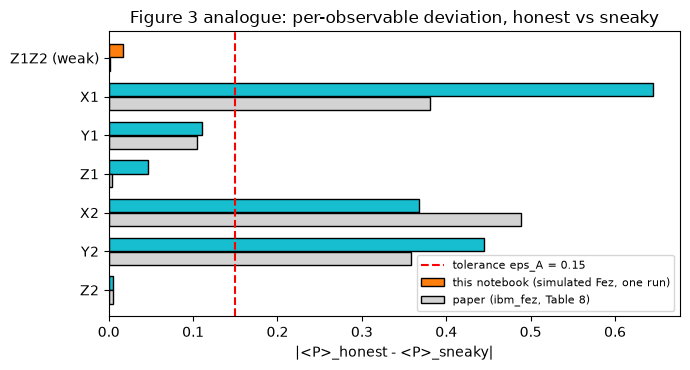

(71 s)


In [13]:
PAPER_T8 = {"ZZ": 0.001, "X1": 0.381, "Y1": 0.105, "Z1": 0.004, "X2": 0.489, "Y2": 0.358, "Z2": 0.005}

def e1_run(seed, nm_sim=SIM_NOISY, shots=SHOTS_PER_OBS):
    fh = measure_fp("honest", OBS7, nm_sim, shots, seed)
    fs = measure_fp("sneaky", OBS7, nm_sim, shots, seed + 7919)           # independent shot noise, as on hardware
    return fh, fs

t = time.time()
fh, fs = e1_run(SEED)
dev1 = np.abs(fh - fs)
ideal_dev = np.abs(FP_IDEAL["honest"] - FP_IDEAL["sneaky"])
reps = np.array([np.abs(np.subtract(*e1_run(SEED + 1000 * (r + 1)))) for r in range(N_REPEAT_E1)])
tab8 = pd.DataFrame({"paper (ibm_fez)": pd.Series(PAPER_T8), "exact (noise-free)": pd.Series(ideal_dev, index=OBS7),
                     "this run (seed 42)": pd.Series(dev1, index=OBS7), f"mean over {N_REPEAT_E1} runs": pd.Series(reps.mean(0), index=OBS7),
                     "std": pd.Series(reps.std(0), index=OBS7)})
tab8["within eps_A (this run)?"] = np.where(tab8["this run (seed 42)"] <= EPS_A, "yes", "no")
tab8["paper within eps_A?"] = np.where(tab8["paper (ibm_fez)"] <= EPS_A, "yes", "no")
display(tab8.round(3))
weak_dev, comp_dev = dev1[0], dev1[1:].max()
print(f"verdict, weak contract (Z1Z2 only):  {'accept' if weak_dev <= EPS_A else 'halt'} (max deviation {weak_dev:.3f})        paper: accept (0.001)")
print(f"verdict, complete contract (6 Paulis): {'halt' if comp_dev > EPS_A else 'accept'} (max deviation {comp_dev:.3f} = {comp_dev/EPS_A:.1f} x tolerance)   paper: halt (0.489 = 3.3 x)")
halt_rate = float((reps[:, 1:].max(1) > EPS_A).mean()); weak_accept_rate = float((reps[:, 0] <= EPS_A).mean())
n_exceed = (reps[:, 1:] > EPS_A).sum(1)
print(f"over {N_REPEAT_E1} independent runs: complete contract halts in {halt_rate:.0%}, weak contract accepts in {weak_accept_rate:.0%}; "
      f"observables beyond tolerance per run: mean {n_exceed.mean():.2f} (min {n_exceed.min()}, max {n_exceed.max()})  [paper: 3 of 6]")
print(f"Z-type deviations (Z1Z2, Z1, Z2): mean {reps[:, [0, 3, 6]].mean():.3f} (expected for two independent 2,280-shot estimates: ~{np.sqrt(2/np.pi)*np.sqrt(2/SHOTS_PER_OBS):.3f});  paper: 0.001, 0.004, 0.005")
RES.update(e1_weak_dev=float(weak_dev), e1_comp_dev=float(comp_dev), e1_halt_rate=halt_rate, e1_weak_accept=weak_accept_rate, e1_nexceed_mean=float(n_exceed.mean()),
           e1_dev1=dev1.tolist(), e1_reps_mean=reps.mean(0).tolist(), e1_z_mean=float(reps[:, [0, 3, 6]].mean()), e1_y1_below=float((reps[:, 2] <= EPS_A).mean()))

# Figure 3 analogue
fig, ax = plt.subplots(figsize=(7, 3.8))
order = ["ZZ", "X1", "Y1", "Z1", "X2", "Y2", "Z2"]
ypos = np.arange(len(order))[::-1]
ax.barh(ypos + 0.18, [dev1[OBS7.index(o)] for o in order], height=0.34, color=["tab:orange" if o == "ZZ" else "tab:cyan" for o in order], edgecolor="k", label="this notebook (simulated Fez, one run)")
ax.barh(ypos - 0.18, [PAPER_T8[o] for o in order], height=0.34, color="lightgrey", edgecolor="k", label="paper (ibm_fez, Table 8)")
ax.axvline(EPS_A, color="r", ls="--", label="tolerance eps_A = 0.15")
ax.set_yticks(ypos); ax.set_yticklabels(["Z1Z2 (weak)" if o == "ZZ" else o for o in order]); ax.set_xlabel("|<P>_honest - <P>_sneaky|")
ax.set_title("Figure 3 analogue: per-observable deviation, honest vs sneaky"); ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()
print(f"({time.time()-t:.0f} s)")

### Does the detection depend on the reference input?

Theorem 1 guarantees a deviation only on a *witness* state; Algorithm 1 uses one fixed reference input. The `S` substitution rotates the Bloch vector of each qubit about `Z`; a qubit whose Bloch vector is already
along `Z` (for example the state `|00>` obtained when `x_i = x_j`) shows **no** change in any local Pauli expectation. The cell computes the exact (noise-free) maximum deviation for every ordered pair of the 20 data points as reference input.

S-gate substitution, exact max deviation over the 6 local Paulis for 380 ordered pairs (i != j): min 0.166, median 0.863, max 1.385
fraction of reference pairs with deviation > eps_A = 0.15: 100.0%;  same-point pairs (x_i = x_j): max deviation 6.3e-16
the paper's pair (0.4, 1.2) / (1.1, 0.3): 0.691


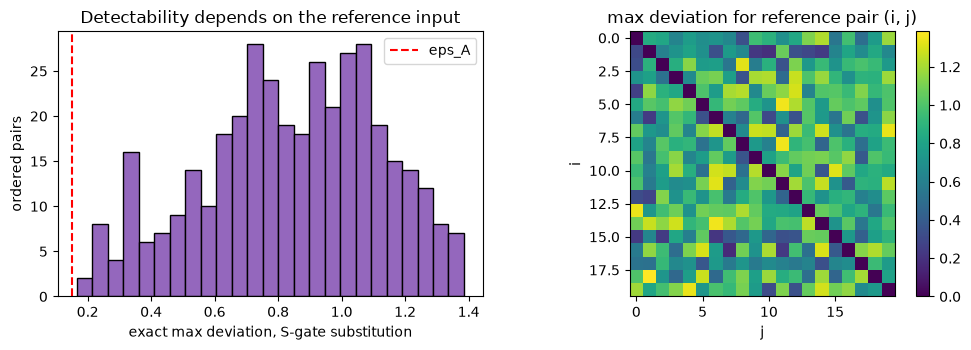

In [14]:
def max_dev_pair(i, j, kind="sneaky"):
    a = fp_exact("honest", OBS6, X[i], X[j]); b = fp_exact(kind, OBS6, X[i], X[j])
    return np.abs(a - b).max()
pair_dev = np.array([[max_dev_pair(i, j) for j in range(N_SAMPLES)] for i in range(N_SAMPLES)])
offdiag = pair_dev[~np.eye(N_SAMPLES, dtype=bool)]
print(f"S-gate substitution, exact max deviation over the 6 local Paulis for {offdiag.size} ordered pairs (i != j): "
      f"min {offdiag.min():.3f}, median {np.median(offdiag):.3f}, max {offdiag.max():.3f}")
print(f"fraction of reference pairs with deviation > eps_A = {EPS_A}: {np.mean(offdiag > EPS_A):.1%};  same-point pairs (x_i = x_j): max deviation {np.diag(pair_dev).max():.1e}")
print(f"the paper's pair (0.4, 1.2) / (1.1, 0.3): {np.abs(FP_IDEAL['honest'][1:] - FP_IDEAL['sneaky'][1:]).max():.3f}")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].hist(offdiag, bins=25, color="tab:purple", edgecolor="k"); axs[0].axvline(EPS_A, color="r", ls="--", label="eps_A"); axs[0].set_xlabel("exact max deviation, S-gate substitution"); axs[0].set_ylabel("ordered pairs"); axs[0].legend()
axs[0].set_title("Detectability depends on the reference input")
im = axs[1].imshow(pair_dev, cmap="viridis"); axs[1].set_title("max deviation for reference pair (i, j)"); axs[1].set_xlabel("j"); axs[1].set_ylabel("i"); plt.colorbar(im, ax=axs[1])
plt.tight_layout(); plt.show()
RES.update(pair_frac_detect=float(np.mean(offdiag > EPS_A)), pair_min=float(offdiag.min()), pair_median=float(np.median(offdiag)))

## 4. Experiment 2: how many shots does an informative check need? (paper Table 9, Figure 4)

The paper uses the **weakened** sneaky channel (`RZ(pi/6)` on each qubit, true maximum deviation 0.259, only moderately above `eps_A = 0.15`) and a **noise-free reference** fingerprint of the honest channel (ideal simulator, 100,000 shots per observable).
At each per-observable budget it runs independent trials with fresh seeds: a *sneaky* trial is a **true positive** if the largest deviation over the six observables exceeds `eps_A`; an *honest* trial that exceeds it is a **false positive**.
Definition 4: detection is *informative* only if TPR >= 1 - eta = 0.95 **and** FPR <= eta = 0.05. Budgets: the paper's `n_O = 2280` (Corollary 1), 228 and 22; we add a finer grid.

noise-free reference fingerprint (1e5 shots): [-0.298 -0.392  0.768  0.492 -0.065  0.763] | exact: [-0.298 -0.393  0.767  0.494 -0.066  0.763]


E2 simulation: 10 budgets x 200 trials x 2 channels in 392 s
Table 9 analogue, paper protocol (first 20 trials) next to the paper's values:


,n_per_obs,N_total,TPR,TPR_CI,FPR,FPR_CI,informative,paper TPR,paper FPR
0,2280,13680,1.00,"[0.84, 1.00]",0.00,"[0.00, 0.16]",True,1.0,0.0
1,1710,10260,1.00,"[0.84, 1.00]",0.00,"[0.00, 0.16]",True,-,-
2,1140,6840,1.00,"[0.84, 1.00]",0.00,"[0.00, 0.16]",True,-,-
3,855,5130,1.00,"[0.84, 1.00]",0.00,"[0.00, 0.16]",True,-,-
4,570,3420,1.00,"[0.84, 1.00]",0.00,"[0.00, 0.16]",True,-,-
5,400,2400,1.00,"[0.84, 1.00]",0.00,"[0.00, 0.16]",True,-,-
6,228,1368,0.95,"[0.76, 0.99]",0.40,"[0.22, 0.61]",False,0.95,0.15
7,114,684,1.00,"[0.84, 1.00]",0.65,"[0.43, 0.82]",False,-,-
8,57,342,1.00,"[0.84, 1.00]",0.95,"[0.76, 0.99]",False,-,-
9,22,132,1.00,"[0.84, 1.00]",0.95,"[0.76, 0.99]",False,1.0,1.0


Same experiment with 200 trials per budget (tighter confidence intervals):


,n_per_obs,N_total,TPR,TPR_CI,FPR,FPR_CI,informative
0,2280,13680,1.00,"[0.98, 1.00]",0.000,"[0.00, 0.02]",True
1,1710,10260,1.00,"[0.98, 1.00]",0.000,"[0.00, 0.02]",True
2,1140,6840,1.00,"[0.98, 1.00]",0.000,"[0.00, 0.02]",True
3,855,5130,1.00,"[0.98, 1.00]",0.000,"[0.00, 0.02]",True
4,570,3420,1.00,"[0.98, 1.00]",0.030,"[0.01, 0.06]",True
5,400,2400,1.00,"[0.98, 1.00]",0.105,"[0.07, 0.16]",False
6,228,1368,0.99,"[0.96, 1.00]",0.310,"[0.25, 0.38]",False
7,114,684,0.99,"[0.96, 1.00]",0.580,"[0.51, 0.65]",False
8,57,342,0.98,"[0.95, 0.99]",0.830,"[0.77, 0.88]",False
9,22,132,1.00,"[0.98, 1.00]",0.950,"[0.91, 0.97]",False


true maximum deviation of the weakened channel (exact, noise-free): 0.256   (paper: 0.259)
honest channel on the simulated Fez vs the noise-free reference, noise-only max deviation: 0.082 (tolerance 0.15)


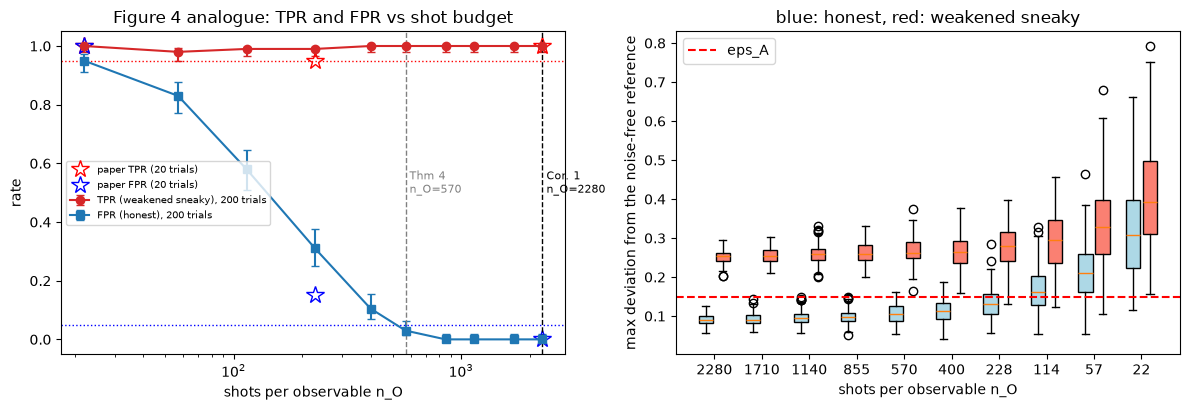

In [15]:
t = time.time()
REF_IDEAL = measure_fp("honest", OBS6, SIM_IDEAL, 100000, SEED)            # noise-free reference at 1e5 shots per observable (as in the paper)
print("noise-free reference fingerprint (1e5 shots):", REF_IDEAL.round(3), "| exact:", FP_IDEAL["honest"][1:].round(3))

def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return max(0.0, c - h), min(1.0, c + h)

maxdev_h = np.zeros((len(BUDGETS_E2), N_TRIALS_E2)); maxdev_s = np.zeros_like(maxdev_h)
for bi, nO in enumerate(BUDGETS_E2):
    for tr in range(N_TRIALS_E2):
        s0 = SEED + 100003 * bi + 17 * tr
        maxdev_h[bi, tr] = np.abs(measure_fp("honest", OBS6, SIM_NOISY, nO, s0) - REF_IDEAL).max()
        maxdev_s[bi, tr] = np.abs(measure_fp("weak", OBS6, SIM_NOISY, nO, s0 + 5) - REF_IDEAL).max()
print(f"E2 simulation: {len(BUDGETS_E2)} budgets x {N_TRIALS_E2} trials x 2 channels in {time.time()-t:.0f} s")

def rates(n_tr):
    out = []
    for bi, nO in enumerate(BUDGETS_E2):
        fp_k, tp_k = int((maxdev_h[bi, :n_tr] > EPS_A).sum()), int((maxdev_s[bi, :n_tr] > EPS_A).sum())
        lo_f, hi_f = wilson(fp_k, n_tr); lo_t, hi_t = wilson(tp_k, n_tr)
        out.append(dict(n_per_obs=nO, N_total=6 * nO, TPR=tp_k / n_tr, TPR_CI=f"[{lo_t:.2f}, {hi_t:.2f}]", FPR=fp_k / n_tr, FPR_CI=f"[{lo_f:.2f}, {hi_f:.2f}]",
                        informative=bool(tp_k / n_tr >= 1 - ETA and fp_k / n_tr <= ETA)))
    return pd.DataFrame(out)
t9_paper = rates(20); t9_full = rates(N_TRIALS_E2)
paper_t9 = pd.DataFrame({"n_per_obs": [2280, 228, 22], "paper TPR": [1.00, 0.95, 1.00], "paper FPR": [0.00, 0.15, 1.00]})
print("Table 9 analogue, paper protocol (first 20 trials) next to the paper's values:")
display(t9_paper.merge(paper_t9, on="n_per_obs", how="left").fillna("-"))
print(f"Same experiment with {N_TRIALS_E2} trials per budget (tighter confidence intervals):")
display(t9_full)
true_dev_weak_ref = np.abs(FP_IDEAL["honest"][1:] - FP_IDEAL["weak"][1:]).max()
print(f"true maximum deviation of the weakened channel (exact, noise-free): {true_dev_weak_ref:.3f}   (paper: 0.259)")
print(f"honest channel on the simulated Fez vs the noise-free reference, noise-only max deviation: {RES['honest_noise_dev_max']:.3f} (tolerance {EPS_A})")
RES.update(t9_paper=t9_paper.to_dict("records"), t9_full=t9_full.to_dict("records"), true_dev_weak=float(true_dev_weak_ref))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.array(BUDGETS_E2)
lo = [wilson(int((maxdev_s[b] > EPS_A).sum()), N_TRIALS_E2) for b in range(len(x))]; lo2 = [wilson(int((maxdev_h[b] > EPS_A).sum()), N_TRIALS_E2) for b in range(len(x))]
axs[0].errorbar(x, t9_full["TPR"], yerr=[np.array(t9_full["TPR"]) - [a for a, b in lo], [b for a, b in lo] - np.array(t9_full["TPR"])], fmt="o-", color="tab:red", label=f"TPR (weakened sneaky), {N_TRIALS_E2} trials", capsize=3)
axs[0].errorbar(x, t9_full["FPR"], yerr=[np.array(t9_full["FPR"]) - [a for a, b in lo2], [b for a, b in lo2] - np.array(t9_full["FPR"])], fmt="s-", color="tab:blue", label=f"FPR (honest), {N_TRIALS_E2} trials", capsize=3)
axs[0].plot([2280, 228, 22], [1.00, 0.95, 1.00], "r*", ms=13, mfc="none", label="paper TPR (20 trials)"); axs[0].plot([2280, 228, 22], [0.00, 0.15, 1.00], "b*", ms=13, mfc="none", label="paper FPR (20 trials)")
axs[0].axhline(1 - ETA, color="r", ls=":", lw=1); axs[0].axhline(ETA, color="b", ls=":", lw=1)
axs[0].axvline(N_thm4(6, gam) / 6, color="grey", ls="--", lw=1); axs[0].text(N_thm4(6, gam) / 6, 0.5, " Thm 4\n n_O=570", fontsize=8, color="grey")
axs[0].axvline(2280, color="k", ls="--", lw=1); axs[0].text(2280, 0.5, " Cor. 1\n n_O=2280", fontsize=8)
axs[0].set_xscale("log"); axs[0].set_xlabel("shots per observable n_O"); axs[0].set_ylabel("rate"); axs[0].set_ylim(-0.05, 1.05); axs[0].legend(fontsize=7, loc="center left")
axs[0].set_title("Figure 4 analogue: TPR and FPR vs shot budget")
axs[1].boxplot([maxdev_h[b] for b in range(len(x))], positions=np.arange(len(x)) - 0.18, widths=0.3, patch_artist=True, boxprops=dict(facecolor="lightblue"), manage_ticks=False)
axs[1].boxplot([maxdev_s[b] for b in range(len(x))], positions=np.arange(len(x)) + 0.18, widths=0.3, patch_artist=True, boxprops=dict(facecolor="salmon"), manage_ticks=False)
axs[1].axhline(EPS_A, color="r", ls="--", label="eps_A"); axs[1].set_xticks(np.arange(len(x))); axs[1].set_xticklabels(x)
axs[1].set_xlabel("shots per observable n_O"); axs[1].set_ylabel("max deviation from the noise-free reference"); axs[1].set_title("blue: honest, red: weakened sneaky"); axs[1].legend()
plt.tight_layout(); plt.show()

## 5. Experiment 3: drift and the tolerance interval (paper Tables 10-11, Figure 5)

The paper runs the honest channel three times inside one job ("timepoints" minutes apart) and defines `d_typ = max_{i<j} max_O |Fp_i[O] - Fp_j[O]|`. The tolerance must lie in `[d_typ, delta_min / C]` with
`delta_min = 0.5`, so the upper end is `0.5 / sqrt(3) = 0.289`.

Three versions are run here:

* **(a) static device** (the protocol as in the paper, with *no* change of calibration): the measured `d_typ` is then pure shot noise, which sets the floor against which "drift" must be judged;
* **(b) calibration jitter**: each timepoint uses a new calibration snapshot in which every error rate, T1 and T2 is multiplied by `exp(sigma N(0,1))`;
* **(c) systematic degradation**: all error rates multiplied by a factor, T1/T2 divided by it, compared with the reference of the well-calibrated device and with the noise-free reference.

Table 11 analogue (static simulated device, first run):


,quantity,paper,this run,mean +- std over 200 runs
0,max|Fp(t1)-Fp(t2)|,0.067,0.042,0.044 +- 0.015
1,max|Fp(t1)-Fp(t3)|,0.067,0.042,0.044 +- 0.015
2,max|Fp(t2)-Fp(t3)|,0.046,0.047,0.044 +- 0.015
3,d_typ,0.067,0.047,0.054 +- 0.014
4,tolerance interval,"[0.067, 0.289]","[0.047, 0.289]","[0.054, 0.289]"
5,interval non-empty?,yes,yes,100% of runs
6,recommended eps_A (midpoint),0.178,0.168,0.172


analytic shot-noise std of one pairwise difference per observable: [0.029 0.028 0.022 0.027 0.03  0.022] -> expected max over 6 observables ~ 0.033


(b) three calibration snapshots with log-normal jitter sigma (50 repeats each):


,sigma,d_typ_mean,d_typ_std,d_typ_max,frac_below_eps_A,interval_nonempty,recommended_eps_mean
0,0.00,0.054,0.014,0.087,1.00,1.0,0.171
1,0.10,0.054,0.014,0.082,1.00,1.0,0.171
2,0.25,0.059,0.016,0.091,1.00,1.0,0.174
3,0.50,0.084,0.031,0.185,0.94,1.0,0.186
4,1.00,0.161,0.082,0.413,0.56,0.9,0.225


(c) honest channel on a device whose errors are k times worse (100 runs each, eps_A = 0.15):


,error_scale,dev_vs_calibrated_ref,halt_rate_vs_calibrated_ref,dev_vs_noise_free_ref,halt_rate_vs_noise_free_ref
0,1.0,0.031,0.00,0.092,0.00
1,1.5,0.052,0.00,0.130,0.07
2,2.0,0.085,0.00,0.166,0.92
3,3.0,0.153,0.56,0.235,1.00
4,4.0,0.213,1.00,0.295,1.00
5,6.0,0.318,1.00,0.400,1.00
6,8.0,0.403,1.00,0.485,1.00


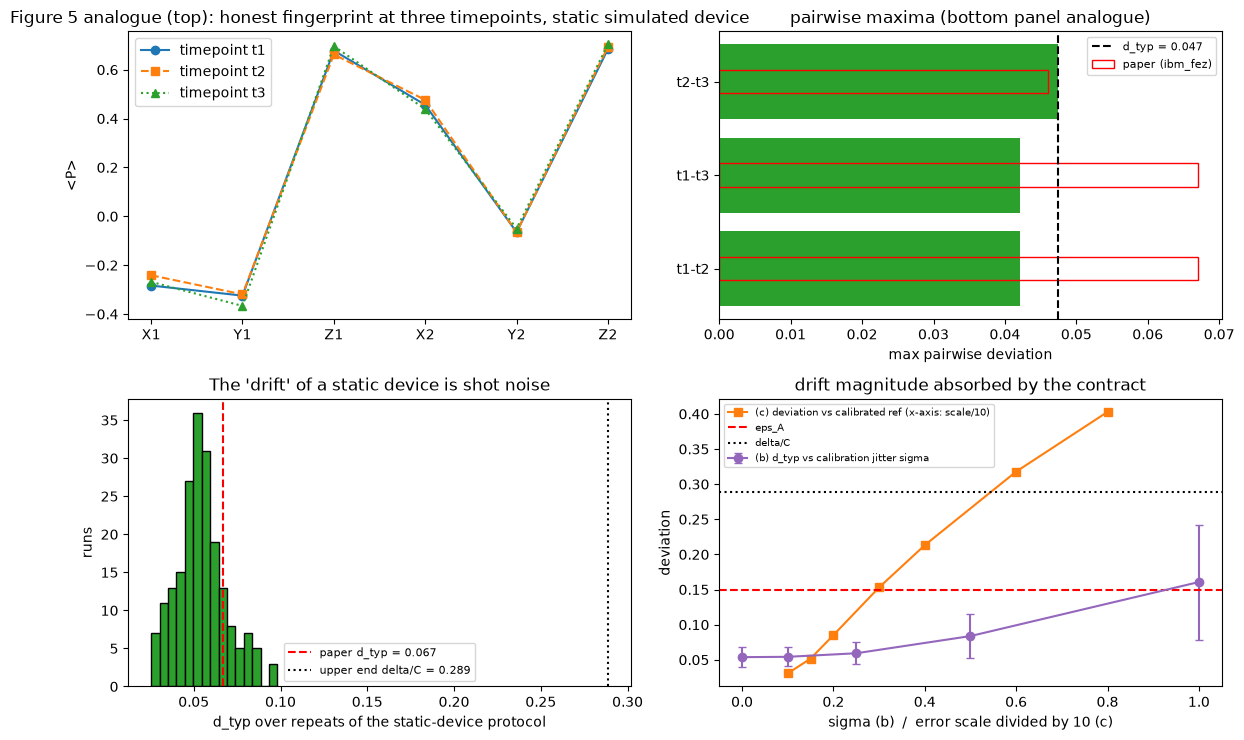

(442 s)


In [16]:
t = time.time()
def drift_protocol(sims, shots, seed):
    fps = np.array([measure_fp("honest", OBS6, s, shots, seed + 31 * k) for k, s in enumerate(sims)])
    pair = [(0, 1), (0, 2), (1, 2)]
    return fps, np.array([np.abs(fps[i] - fps[j]).max() for i, j in pair])

UPPER = DELTA / C_LOCAL
# (a) static device: the protocol repeated
runs_a = [drift_protocol([SIM_NOISY] * 3, SHOTS_PER_OBS, SEED + 1000 * r) for r in range(N_REPEAT_E3)]
dtyp_a = np.array([d.max() for _, d in runs_a]); pw_a = np.array([d for _, d in runs_a])
fps0, pw0 = runs_a[0]
print("Table 11 analogue (static simulated device, first run):")
display(pd.DataFrame({"quantity": ["max|Fp(t1)-Fp(t2)|", "max|Fp(t1)-Fp(t3)|", "max|Fp(t2)-Fp(t3)|", "d_typ", "tolerance interval", "interval non-empty?", "recommended eps_A (midpoint)"],
                      "paper": [0.067, 0.067, 0.046, 0.067, "[0.067, 0.289]", "yes", 0.178],
                      "this run": [*pw0.round(3), round(pw0.max(), 3), f"[{pw0.max():.3f}, {UPPER:.3f}]", "yes" if pw0.max() < UPPER else "no", round((pw0.max() + UPPER) / 2, 3)],
                      f"mean +- std over {N_REPEAT_E3} runs": [*[f"{m:.3f} +- {s:.3f}" for m, s in zip(pw_a.mean(0), pw_a.std(0))], f"{dtyp_a.mean():.3f} +- {dtyp_a.std():.3f}",
                                                         f"[{dtyp_a.mean():.3f}, {UPPER:.3f}]", f"{(dtyp_a < UPPER).mean():.0%} of runs", f"{((dtyp_a + UPPER) / 2).mean():.3f}"]}))
# expected shot-noise floor from the binomial variance of the two estimates
mu_h = FP_H_NOISY[1:]
floor = np.sqrt(2 * (1 - mu_h**2) / SHOTS_PER_OBS)
print("analytic shot-noise std of one pairwise difference per observable:", floor.round(3), "-> expected max over 6 observables ~ %.3f" % (np.sqrt(np.pi / 2) * floor.max() * 0.9))
RES.update(dtyp_a=float(dtyp_a.mean()), dtyp_a_std=float(dtyp_a.std()), dtyp_a_first=float(pw0.max()), pw0=pw0.tolist(), upper=UPPER, mid_a=float(((dtyp_a + UPPER) / 2).mean()), nonempty_a=float((dtyp_a < UPPER).mean()))

# (b) calibration jitter between snapshots
rows_b = []
for sg in SIGMAS_E3:
    vals = []
    for r in range(N_REPEAT_SIG):
        rr = np.random.default_rng(SEED + 7 * r + int(1000 * sg))
        sims = [AerSimulator(noise_model=noise_from_calib(perturb_calib(CAL0, rr, sigma=sg))) for _ in range(3)]
        vals.append(drift_protocol(sims, SHOTS_PER_OBS, SEED + 1000 * r)[1].max())
    vals = np.array(vals)
    rows_b.append(dict(sigma=sg, d_typ_mean=vals.mean(), d_typ_std=vals.std(), d_typ_max=vals.max(), frac_below_eps_A=float((vals <= EPS_A).mean()),
                       interval_nonempty=float((vals < UPPER).mean()), recommended_eps_mean=float(((vals + UPPER) / 2).mean())))
tab_b = pd.DataFrame(rows_b)
print(f"(b) three calibration snapshots with log-normal jitter sigma ({N_REPEAT_SIG} repeats each):")
display(tab_b.round(3))

# (c) systematic degradation vs reference
REF_CAL = measure_fp("honest", OBS6, SIM_NOISY, 100000, SEED)                 # fingerprint of the well-calibrated device (1e5 shots)
rows_c = []
for k in SCALES_E3:
    sim_k = AerSimulator(noise_model=noise_from_calib(perturb_calib(CAL0, np.random.default_rng(0), sigma=0.0, scale=k)))
    dc, di = [], []
    for r in range(N_REPEAT_SCALE):
        fp = measure_fp("honest", OBS6, sim_k, SHOTS_PER_OBS, SEED + 13 * r)
        dc.append(np.abs(fp - REF_CAL).max()); di.append(np.abs(fp - FP_IDEAL["honest"][1:]).max())
    rows_c.append(dict(error_scale=k, dev_vs_calibrated_ref=np.mean(dc), halt_rate_vs_calibrated_ref=float((np.array(dc) > EPS_A).mean()),
                       dev_vs_noise_free_ref=np.mean(di), halt_rate_vs_noise_free_ref=float((np.array(di) > EPS_A).mean())))
tab_c = pd.DataFrame(rows_c)
print(f"(c) honest channel on a device whose errors are k times worse ({N_REPEAT_SCALE} runs each, eps_A = {EPS_A}):")
display(tab_c.round(3))
RES.update(tab_b=tab_b.to_dict("records"), tab_c=tab_c.to_dict("records"))

# Figure 5 analogue + drift tolerance curves
fig, axs = plt.subplots(2, 2, figsize=(12, 7.5))
mk, ls_ = ["o", "s", "^"], ["-", "--", ":"]
for k in range(3): axs[0, 0].plot(range(6), fps0[k], marker=mk[k], ls=ls_[k], label=f"timepoint t{k+1}")
axs[0, 0].set_xticks(range(6)); axs[0, 0].set_xticklabels(OBS6); axs[0, 0].set_ylabel("<P>"); axs[0, 0].legend(); axs[0, 0].set_title("Figure 5 analogue (top): honest fingerprint at three timepoints, static simulated device")
axs[0, 1].barh(["t1-t2", "t1-t3", "t2-t3"], pw0, color="tab:green"); axs[0, 1].axvline(pw0.max(), color="k", ls="--", label=f"d_typ = {pw0.max():.3f}")
axs[0, 1].barh(["t1-t2", "t1-t3", "t2-t3"], [0.067, 0.067, 0.046], height=0.25, color="none", edgecolor="r", label="paper (ibm_fez)")
axs[0, 1].set_xlabel("max pairwise deviation"); axs[0, 1].legend(fontsize=8); axs[0, 1].set_title("pairwise maxima (bottom panel analogue)")
axs[1, 0].hist(dtyp_a, bins=15, color="tab:green", edgecolor="k"); axs[1, 0].axvline(0.067, color="r", ls="--", label="paper d_typ = 0.067"); axs[1, 0].axvline(UPPER, color="k", ls=":", label="upper end delta/C = 0.289")
axs[1, 0].set_xlabel("d_typ over repeats of the static-device protocol"); axs[1, 0].set_ylabel("runs"); axs[1, 0].legend(fontsize=8); axs[1, 0].set_title("The 'drift' of a static device is shot noise")
axs[1, 1].errorbar(tab_b["sigma"], tab_b["d_typ_mean"], yerr=tab_b["d_typ_std"], fmt="o-", color="tab:purple", label="(b) d_typ vs calibration jitter sigma", capsize=3)
axs[1, 1].plot(tab_c["error_scale"] * 0.1, tab_c["dev_vs_calibrated_ref"], "s-", color="tab:orange", label="(c) deviation vs calibrated ref (x-axis: scale/10)")
axs[1, 1].axhline(EPS_A, color="r", ls="--", label="eps_A"); axs[1, 1].axhline(UPPER, color="k", ls=":", label="delta/C")
axs[1, 1].set_xlabel("sigma (b)  /  error scale divided by 10 (c)"); axs[1, 1].set_ylabel("deviation"); axs[1, 1].legend(fontsize=7); axs[1, 1].set_title("drift magnitude absorbed by the contract")
plt.tight_layout(); plt.show()
print(f"({time.time()-t:.0f} s)")

## 6. Algorithm 1: the dual-mode verifier with an audit trail

Algorithm 1 draws **one** observable per round at random, requests `N/k = 2,280` shots, compares the estimate with the reference fingerprint and either logs a *drift event* or **halts**.
Every entry is chained into a SHA-256 audit trail anchored by the hash of the specification `sigma_A = (H_spec, O_A, eps_A, tau_A)`. The reference is the exact fingerprint of the declared channel (Algorithm 1, line 2).

Below: (i) a demo in which the device drifts from round to round (a fresh calibration snapshot with jitter `sigma = 0.15` each round) and the channel is replaced by the sneaky one after round 8;
(ii) Monte-Carlo runs giving the survival curve `P(no halt after T rounds)` for the sneaky and weakened-sneaky channels, to compare with the soundness remark `(1 - 1/|O_A|)^T`, and for the honest channel under heavier drift
(`sigma = 0.25`), which gives the false-halt rate of the verifier when the reference is the *noise-free* specification.

H_spec = 3ed429ea0dfc1baf92368b7e09b567bd ...


Algorithm 1 returned: Halt


,t,observable,mu,dev,status,ground truth (hidden from the verifier),entry_hash
0,1,X2,0.4544,0.0396,logged as drift event,honest,3f8b023b881b
1,2,X2,0.4526,0.0414,logged as drift event,honest,69650339ca5e
2,3,Z1,0.6991,0.0676,logged as drift event,honest,8f16910222f9
3,4,X1,-0.2509,0.0473,logged as drift event,honest,972e99f20a6d
4,5,X2,0.4386,0.0554,logged as drift event,honest,fd912b444ae6
5,6,X1,-0.2614,0.0368,logged as drift event,honest,17157d05d095
6,7,Y1,-0.3482,0.0445,logged as drift event,honest,b643d7b7436c
7,8,Z2,0.6658,0.0976,logged as drift event,honest,8742d53f13f3
8,9,Z1,0.6886,0.0782,logged as drift event,sneaky,dbad8bc2b954
9,10,X2,0.0640,0.4300,HALT: integrity violation,sneaky,2c542ccd9d25


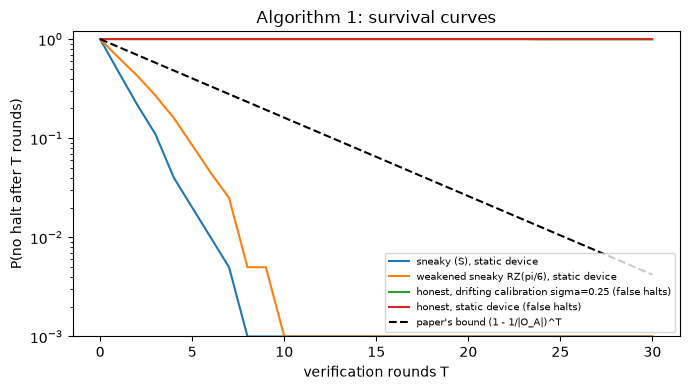

mean rounds to halt: sneaky 1.87, weakened sneaky 2.67; honest runs that halted within 30 rounds: static 0%, drifting 0%
sneaky survival below the paper's (5/6)^T bound for all T (within MC error): True
(569 s)


In [17]:
t = time.time()
SPEC = dict(pipeline="QSVM ZZFeatureMap reps=2 inversion test", x_i=list(XI), x_j=list(XJ), observables=OBS6, eps_A=EPS_A, tau_A="2026-10-19T00:00:00Z",
            reference=[round(float(v), 6) for v in FP_IDEAL["honest"][1:]])
H_SPEC = hashlib.sha256(json.dumps(SPEC, sort_keys=True).encode()).hexdigest()
REF_SPEC = FP_IDEAL["honest"][1:]
print("H_spec =", H_SPEC[:32], "...")

def run_verifier(schedule, rng_v, ref=REF_SPEC, eps=EPS_A, shots=int(np.ceil(6 * SHOTS_PER_OBS / 6)), seed0=0):
    prev, audit = H_SPEC, []
    for tt, (kind, sim) in enumerate(schedule, 1):
        o = OBS6[int(rng_v.integers(len(OBS6)))]                         # line 4: uniformly random observable
        mu = float(measure_fp(kind, [o], sim, shots, seed0 + tt)[0])      # lines 5-6
        dev = abs(mu - ref[OBS6.index(o)])                                # line 7
        status = "HALT: integrity violation" if dev > eps else "logged as drift event"
        body = dict(t=tt, observable=o, mu=round(mu, 4), dev=round(dev, 4), status=status)
        prev = hashlib.sha256((prev + json.dumps(body, sort_keys=True)).encode()).hexdigest()
        audit.append(dict(**body, truth=kind, entry_hash=prev[:12]))
        if dev > eps:
            return "Halt", audit
    return "Accept", audit

# (i) demo: honest with drifting calibration for 8 rounds, then the sneaky channel
r_demo = np.random.default_rng(SEED)
def drift_sim(sigma, rr): return AerSimulator(noise_model=noise_from_calib(perturb_calib(CAL0, rr, sigma=sigma)))
sched = [("honest", drift_sim(0.15, r_demo)) for _ in range(8)] + [("sneaky", drift_sim(0.15, r_demo)) for _ in range(12)]
verdict, audit = run_verifier(sched, np.random.default_rng(SEED + 1), seed0=SEED)
print("Algorithm 1 returned:", verdict)
display(pd.DataFrame(audit).rename(columns={"truth": "ground truth (hidden from the verifier)"}))

# (ii) Monte Carlo
POOL = {s: [drift_sim(s, np.random.default_rng(100 + n)) for n in range(15)] for s in (0.0, 0.25)}
def mc(kind, sigma, n_trials, seed):
    halts = []
    for tr in range(n_trials):
        rv = np.random.default_rng(seed + tr)
        sch = [(kind, POOL[sigma][int(rv.integers(len(POOL[sigma])))]) for _ in range(MAX_ROUNDS)]
        verdict, aud = run_verifier(sch, rv, seed0=seed + 1000 * tr)
        halts.append(len(aud) if verdict == "Halt" else np.inf)
    return np.array(halts)
H_sneaky = mc("sneaky", 0.0, N_ALG1_TRIALS, 10)
H_weak   = mc("weak", 0.0, N_ALG1_TRIALS, 20)
H_honest = mc("honest", 0.25, N_ALG1_TRIALS, 30)
H_honest0 = mc("honest", 0.0, N_ALG1_TRIALS, 40)
Ts = np.arange(0, MAX_ROUNDS + 1)
surv = lambda H: np.array([(H > T).mean() for T in Ts])
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(Ts, np.maximum(surv(H_sneaky), 1e-3), label="sneaky (S), static device"); ax.semilogy(Ts, np.maximum(surv(H_weak), 1e-3), label="weakened sneaky RZ(pi/6), static device")
ax.semilogy(Ts, np.maximum(surv(H_honest), 1e-3), label="honest, drifting calibration sigma=0.25 (false halts)"); ax.semilogy(Ts, np.maximum(surv(H_honest0), 1e-3), label="honest, static device (false halts)")
ax.semilogy(Ts, (1 - 1 / 6) ** Ts, "k--", label="paper's bound (1 - 1/|O_A|)^T"); ax.set_ylim(1e-3, 1.2)
ax.set_xlabel("verification rounds T"); ax.set_ylabel("P(no halt after T rounds)"); ax.legend(fontsize=7); ax.set_title("Algorithm 1: survival curves"); plt.tight_layout(); plt.show()
mean_rounds = lambda H: float(np.mean(np.where(np.isfinite(H), H, MAX_ROUNDS)))
print(f"mean rounds to halt: sneaky {mean_rounds(H_sneaky):.2f}, weakened sneaky {mean_rounds(H_weak):.2f}; honest runs that halted within {MAX_ROUNDS} rounds: static {np.isfinite(H_honest0).mean():.0%}, drifting {np.isfinite(H_honest).mean():.0%}")
bound_ok = bool(np.all(surv(H_sneaky) <= (1 - 1 / 6) ** Ts + 2 / np.sqrt(N_ALG1_TRIALS)))
print("sneaky survival below the paper's (5/6)^T bound for all T (within MC error):", bound_ok)
RES.update(alg1_mean_sneaky=mean_rounds(H_sneaky), alg1_mean_weak=mean_rounds(H_weak), alg1_false_static=float(np.isfinite(H_honest0).mean()), alg1_false_drift=float(np.isfinite(H_honest).mean()), alg1_bound_ok=bound_ok)
print(f"({time.time()-t:.0f} s)")

## 7. Side-by-side comparison with the paper

Tolerances for the verdicts: closed-form quantities within 1 %; frame-bound constants within 0.02; deviations within 0.05 absolute; rates from 20 trials within 0.10 (one binomial standard error at p = 0.5 is 0.11);
`d_typ` within 0.02. "Exceeded" / "not reached" give the gap when the notebook is above / below the paper's value.

In [18]:
rows = []
def add(claim, paper, mine, verdict, note=""):
    rows.append(dict(claim=claim, paper=paper, notebook=mine, verdict=verdict, note=note))
def num(claim, paper, mine, tol, fmt="{:.3f}", rel=False, note=""):
    gap = mine - paper; ok = abs(gap) <= (tol * abs(paper) if rel else tol)
    add(claim, fmt.format(paper), fmt.format(mine), "reproduced" if ok else (f"exceeded by {fmt.format(gap)}" if gap > 0 else f"not reached (lower by {fmt.format(-gap)})"), note)
def boolean(claim, paper, mine, note=""):
    add(claim, str(paper), str(mine), "reproduced" if paper == mine else "not reproduced", note)

# theory
num("margin gamma = delta/C - eps_A", 0.139, RES["gamma"], 0.002)
num("Theorem 4 budget N", 3420, RES["N_thm4"], 0.01, "{:,.0f}", rel=True)
num("Corollary 1 budget N", 13680, RES["N_cor1"], 0.01, "{:,.0f}", rel=True, note="paper rounds gamma to 0.139")
num("reduction vs C = 2 sqrt(2) ('~27-fold')", 27, RES["fold27"], 0.05, "{:.1f}", rel=True)
num("asymptotic reduction 8/3", 8 / 3, RES["asym"], 0.01, "{:.3f}", rel=True)
num("combined reduction ('~100-fold')", 100, RES["fold_comb"], 0.10, "{:.0f}", rel=True, note="107 = 26.8 x 4; 'approximately 100'")
num("C(6 local Paulis) = sqrt(3)", float(np.sqrt(3)), RES["C6"], 0.02)
num("C(9 observables) ~ 2.21", 2.21, RES["C9"], 0.02)
num("C(15 observables) ~ 3.73", 3.73, RES["C15"], 0.02)
num("Tier 2 budget N (Cor. 1)", 72700, RES["N_tier2"], 0.03, "{:,.0f}", rel=True)
num("Tier 3 budget N at eps_A = 0.05, eta = 0.05", 1.4e5, RES["N_tier3"], 0.05, "{:,.0f}", rel=True, note=f"eta = 0.01 would give {RES['N_tier3_eta001']:,.0f}")
r_s, r_w, r_h = RES["thm1_rows"]
boolean("Theorem 1: Delta >= delta/C for the S-gate substitution", True, r_s["holds_full_convention"])
boolean("Theorem 1: Delta >= delta/C for the RZ(pi/6) substitution (diamond norm without 1/2)", True, r_w["holds_full_convention"], "holds only with delta = (1/2)||.||_diamond")
# experiment 1
boolean("Exp. 1: weak contract accepts the sneaky channel", True, RES["e1_weak_accept"] >= 0.95, f"accept rate {RES['e1_weak_accept']:.0%} over repeats")
num("Exp. 1: weak-contract deviation (Z1Z2)", 0.001, RES["e1_weak_dev"], 0.05, note="independent shot noise gives ~0.02 per estimate pair")
boolean("Exp. 1: complete contract halts", True, RES["e1_halt_rate"] >= 0.95, f"halt rate {RES['e1_halt_rate']:.0%} over repeats")
num("Exp. 1: worst complete-family deviation", 0.489, RES["e1_comp_dev"], 0.05)
num("Exp. 1: observables beyond tolerance (of 6)", 3, RES["e1_nexceed_mean"], 0.5, "{:.2f}")
for o, pv in [("X1", 0.381), ("Y1", 0.105), ("X2", 0.489), ("Y2", 0.358)]:
    num(f"Exp. 1: deviation on {o}", pv, RES["e1_dev1"][OBS7.index(o)], 0.05)
boolean("Exp. 1: Y1 just below tolerance (within eps_A)", True, RES["e1_y1_below"] >= 0.5, f"within tolerance in {RES['e1_y1_below']:.0%} of runs")
num("Exp. 1: Z-type deviations (mean of Z1Z2, Z1, Z2)", 0.0033, RES["e1_z_mean"], 0.01, note="below 0.01 would be unusual for two independent 2,280-shot estimates (expected ~0.02)")
# experiment 2
num("Exp. 2: true max deviation of the weakened channel", 0.259, RES["true_dev_weak"], 0.01, note=f"paper's text order gives {RES['weak_true_max_text']:.3f}")
for rec in RES["t9_paper"]:
    n = rec["n_per_obs"]
    if n in (2280, 228, 22):
        pt, pf = {2280: (1.0, 0.0), 228: (0.95, 0.15), 22: (1.0, 1.0)}[n]
        num(f"Exp. 2: TPR at n_O = {n} (20 trials)", pt, rec["TPR"], 0.10, "{:.2f}")
        num(f"Exp. 2: FPR at n_O = {n} (20 trials)", pf, rec["FPR"], 0.10, "{:.2f}")
inf_budgets = [r["n_per_obs"] for r in RES["t9_full"] if r["informative"]]
add("Exp. 2: informative detection (TPR>=0.95 and FPR<=0.05) from the Corollary 1 budget, not below", "n_O >= 2280 (N)", f"informative budgets: {inf_budgets}", "reproduced" if 2280 in inf_budgets and 228 not in inf_budgets else "not reproduced",
    "informative detection starts already near the Theorem 4 budget (n_O = 570), i.e. Corollary 1 is conservative by the factor 4, as the paper remarks")
# experiment 3
num("Exp. 3: d_typ (static device, mean over repeats)", 0.067, RES["dtyp_a"], 0.02)
num("Exp. 3: upper end of the interval delta/C", 0.289, RES["upper"], 0.001)
boolean("Exp. 3: interval non-empty", True, RES["nonempty_a"] >= 0.95)
num("Exp. 3: recommended eps_A (midpoint)", 0.178, RES["mid_a"], 0.02)
add("Exp. 3: typical drift is a calibration effect", "d_typ = 0.067 'drift'", f"static device (no calibration change) already gives {RES['dtyp_a']:.3f} +- {RES['dtyp_a_std']:.3f}", "the number is consistent with pure shot noise", "see section 5")
# cannot be checked
for c, why in [("IBM job IDs, queue and QPU times, 22 May 2026 runs", "real hardware not available"), ("absolute ibm_fez deviations of Table 8 / Table 11", "device-specific; simulation only"),
               ("Corollary 2 / eps_A = eps_adv + eps_drift decomposition", "needs diamond-norm distances of noisy channels (SDP) and a drift model"), ("'first hardware validation of a dual-mode contract'", "novelty claim"),
               ("Experiments on VQC, QNN, QCNN, QBM instances", "the paper validates the QSVM instance only")]:
    add(c, "reported", "-", "cannot be checked", why)
cmp_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90, "display.width", 250, "display.max_rows", 200)
display(cmp_df)
def category(v):
    for key in ("reproduced", "exceeded", "not reached", "not reproduced", "cannot be checked"):
        if v.startswith(key): return key
    return "other (see note)"
print(cmp_df["verdict"].map(category).value_counts().to_string())

,claim,paper,notebook,verdict,note
0,margin gamma = delta/C - eps_A,0.139,0.139,reproduced,
1,Theorem 4 budget N,"3,420","3,420",reproduced,
2,Corollary 1 budget N,"13,680","13,680",reproduced,paper rounds gamma to 0.139
3,reduction vs C = 2 sqrt(2) ('~27-fold'),27.0,26.8,reproduced,
4,asymptotic reduction 8/3,2.667,2.667,reproduced,
5,combined reduction ('~100-fold'),100,107,reproduced,107 = 26.8 x 4; 'approximately 100'
6,C(6 local Paulis) = sqrt(3),1.732,1.732,reproduced,
7,C(9 observables) ~ 2.21,2.210,2.209,reproduced,
8,C(15 observables) ~ 3.73,3.730,3.732,reproduced,
9,Tier 2 budget N (Cor. 1),"72,700","72,716",reproduced,


verdict
reproduced           28
exceeded              5
cannot be checked     5
not reached           2
not reproduced        1
other (see note)      1


## 8. Reading the paper critically

* **What is solid.** The core mechanism is simple and correct: a local unitary inserted before a `Z`-basis measurement leaves every `Z` statistic and the SVM kernel untouched, so decision-level audits and a `Z1Z2`-only contract cannot see it, while the `X`/`Y` fingerprint does.
  The closed-form budgets (Theorem 4, Corollary 1, the "27-fold" figure, the Tier-2 number) reproduce. Our simulated device reproduces the *structure* of Table 8 (weak contract accepts, complete contract halts, three of six observables beyond tolerance, `Y1` just below) and the *shape* of Table 9.
* **Theorem 1 and the normalisation of `delta`.** With the diamond norm used in the proof (no factor 1/2, `delta` in [0, 2]) the inequality `Delta >= delta/C` fails for the paper's own `RZ(pi/6)` substitution (0.518 against 0.577), presumably because the proof's witness state may be entangled with an auxiliary system (the frame bound is "extended correspondingly" to it), while the verifier can only prepare inputs on the pipeline's own register. The paper's operational `delta = 0.5` is not tied to a convention.
* **The state in Section 6.1 and the convention.** Taken literally, `U(x_i) U(x_j)^dagger |00>` gives ideal deviations (`Y1` 1.34) that contradict Table 8, whereas the Qiskit kernel order reproduces `Y1` (0.095 vs 0.105) and the 0.259 of Experiment 2 (0.256; the literal order gives 0.47). The paper should state the convention; the choice here was checked against the paper's numbers, which is a (small) degree of freedom.
* **"Drift" in Experiment 3.** Three timepoints minutes apart inside one job measure mostly **shot noise**: a static simulated device gives `d_typ` of the same size as the paper's 0.067. The tolerance interval derived from it says how much shot noise the contract absorbs, not how much calibration drift a day or a week brings. Section 5 (b)-(c) shows what real drift (jitter of the calibration numbers, global degradation) does.
* **Z-type deviations of 0.001 to 0.005.** For two independent 2,280-shot estimates a difference below 0.01 has probability of roughly 0.3 per observable (expected `|difference|` about 0.02); three in a row is possible but unusual. It would be explained if the `Z`-type values came from shared counts.
* **Noise-free vs measured reference.** Honest-channel noise alone puts the largest deviation from the exact fingerprint at about 0.08 to 0.09 on this device model, leaving little of the 0.15 tolerance for drift: in section 5 (c) a device with errors twice as large already halts in most runs against the noise-free reference, but only from about three times larger errors against a reference measured on the calibrated device. Algorithm 1 as written uses the exact specification, so the tolerance has to absorb the static device noise as well as the drift.
* **Reference input dependence.** The fingerprint is measured on one input pair. The `S` substitution is completely invisible when `x_i = x_j` (the state is `|00>`) and, in the noise-free case, exceeds the tolerance for all 380 distinct pairs of the data but with a minimum of only about 0.17 against a median of about 0.86 (section 3); with device noise the weakest pairs are marginal. The soundness argument relies on varying the reference input, which the experiments do not do.
* **The classifier itself.** With the raw coordinates encoded as in the paper, the 20-point QSVM reaches about 60 % test accuracy against 80 to 90 % for classical baselines (section 2). The paper makes no accuracy claim, and the fingerprinting result does not depend on it, but the "stand-in for intrusion detection" is not a good classifier.
* **Scope.** Entangling substitutions, correlated noise and subspace-preserving stealth channels are outside the local family (Appendix A); the complete 15-observable family needs a tighter `eps_A` or about 10 to 100 times more shots. Only a 2-qubit QSVM is validated; VQC/QNN statements are formal.
* **Single run.** The hardware numbers come from one job per experiment; no uncertainty is reported for Table 8 or Table 11.

## 9. Exercises

1. Replace the `S` gates by `Z` gates (a Pauli error before the measurement). Which observables change and does the complete contract still halt? Use `state_circuit` and `fp_exact`.
2. Add an entangling substitution (a `CZ` before the measurement). Show that the six local Paulis do not see it for a product-state input but that adding `Z1Z2`/`X1X2`/`Y1Y2` (Tier 2) does; recompute the shot budget with the notebook's `C(9)`.
3. Choose `eps_A` by Section 5.11 from the (b) sweep for `sigma = 0.25` and report the resulting detection margin and the Corollary 1 budget.
4. Run Algorithm 1 with a reference measured on the calibrated device (`REF_CAL`) instead of the exact specification; compare the false-halt rate for `sigma = 0.25`.
5. Vary the reference pair `(x_i, x_j)` per round (draw from the 20 data points) and measure how many rounds the `S` substitution needs to be caught, compared with the fixed pair of the paper.

In [19]:
print("Total notebook run time: %.1f min (FAST_MODE = %s)" % ((time.time() - T0) / 60, FAST_MODE))

Total notebook run time: 27.9 min (FAST_MODE = False)
